# C + adapter 与纯女足模型 D：沿用 enriched Atomic-VAEP 的分析模式

主比较固定为 **C + Beta adapter vs D**，两条路径都使用 540 场女足开发比赛，并对同一批 231 场测试比赛评分。A、未加 adapter 的 C、新继续训练放在末尾作辅助对照。

分析顺序沿用原 `enriched_atomic_vaep_features_competition_events.ipynb` 的第 4.1–8.2 节：**概率诊断 → 动作差异分布／传球高度／场地区域 → 球员总分 → 每90分钟 → 位置 Top 15 和名单变化**。不是只比较均值，也不把总分和每90分钟混在一张表中。

所有估值差异统一为 **C+adapter − D**；排名差异统一为 **adapter 排名 − D 排名**，正数表示 adapter 给出的名次更靠后。D 是比较对象，不是球员贡献真值。排名相似或名单重合不能证明哪种球员评价更准确。

这里只加载现有模型，不训练。概率和 Atomic-VAEP 公式不变；本次同步原 notebook 的分布图、排名指标、并列规则、小位置组处理及空间图规则。

## 1. 比较模型与分析设置
主图只有 D 与 C+adapter。目录内只保留 540 场适配版本及 ABCD 基础模型。Beta 是当前测试结果下选出的 adapter 类型；修改 `ADAPTER_METHOD` 后，不要继续自动称它为 best。

沿用原 notebook：100 个动作和 45 分钟的球员门槛；动作分布至少 500 条；排名诊断看 Top 10，位置名单看 Top 15，两者不是同一指标。

跨 notebook 的热图显示范围固定：空间差值为 [-0.03, 0.03]，排名人数为 [0, 224]，排名横轴保留 -10 到 +10。6.1 的散点图继续按 position 区分颜色，不随热图调整。

In [1]:
from pathlib import Path
import gc
import json
import sys
import time

import numpy as np
import pandas as pd
from IPython.display import Image, display

HOME = Path.cwd() if (Path.cwd() / 'export_manifest.json').exists() else Path.cwd() / 'atomic_vaep_comparison'
HOME = HOME.resolve()
sys.path.insert(0, str(HOME))
from inference import load_pair, predict_pair, checksum
from analysis import (load_inputs, probability_metrics, atomic_values, player_values, action_summary,
                      spatial_summary, ranking_summary, shortlists, player_changes, comparison_actions,
                      distribution_summary, attach_pass_heights, shortlist_scope, positional_top_comparison,
                      normalization_top_comparison, rank_movement_counts)
from plotting import (LABELS, save_figure, probability_plot, action_plot, spatial_plot,
                      player_plot, action_distribution_plot, position_distribution_plot,
                      rank_movement_plot, position_scatter_plot)

ADAPTER_METHOD = 'beta'
WOMEN_BUDGET = 540
MIN_ACTIONS = 100
MIN_MINUTES = 45
TOP_K = 15
RANK_TOP_K = 10
MIN_TYPE_ACTIONS = 500
ACTION_DELTA_LIMIT = .01
SPATIAL_COLOR_LIMIT = .03
RANK_MOVEMENT_COLOR_MAX = 224
RANK_MOVEMENT_LIMIT = 10
catalog = pd.read_csv(HOME / 'model_catalog.csv').set_index('directory')
c_runs = catalog.loc[(catalog.source == 'C') & (catalog.budget == WOMEN_BUDGET)]
MODEL_PATHS = {
    'A': 'models/A',
    'C': 'models/C',
    'C_adapter': c_runs.loc[c_runs.method == ADAPTER_METHOD].index.item(),
    'C_continued': c_runs.loc[c_runs.method == 'continued_match'].index.item(),
    'D': 'models/D',
}
MAIN_MODELS = ['D', 'C_adapter']
MAIN_PAIRS = [('C_adapter', 'D')]
CONTEXT_PAIRS = [('C', 'D'), ('C_adapter', 'C')]
MAIN_LEFT, MAIN_RIGHT = MAIN_PAIRS[0]
LABELS['C_adapter'] = f'C + {ADAPTER_METHOD.title()} adapter'
RESULTS = HOME / 'results'
FIGURES = RESULTS / 'figures'
RESULTS.mkdir(exist_ok=True)
(RESULTS / 'predictions').mkdir(exist_ok=True)
pd.set_option('display.max_columns', 25)
pd.set_option('display.width', 160)
selected_models = catalog.loc[list(MODEL_PATHS.values()), ['source', 'method', 'budget', 'seed']].copy()
selected_models.insert(0, 'analysis_name', list(MODEL_PATHS))
selected_models.insert(1, 'role', ['main' if model in MAIN_MODELS else 'supporting' for model in MODEL_PATHS])
display(selected_models)
selected_models.to_csv(RESULTS / 'selected_models.csv')

,analysis_name,role,source,method,budget,seed
directory,,,,,,
models/A,A,supporting,A,direct,0,42
models/C,C,supporting,C,direct,0,42
runs/C/beta/b540_s17,C_adapter,main,C,beta,540,17
runs/C/continued_match/b540_s17,C_continued,supporting,C,continued_match,540,17
models/D,D,main,D,direct,540,42


### 1.1 为什么这里用 Beta？
在 540 场预算下，C 的 Beta adapter 在四次运行的平均 test log loss 上，scores 和 concedes 都最低。这里不合并两个不同目标的 loss，也不根据球员排名是否接近 D 来选 adapter。

**这是看到测试结果之后选出的方案。** 后面的比较是探索性分析，不能把同一测试集再次当作独立验证。正式论文需披露这一点；若要独立验证，应另用未参与选择的数据。下表保留所有候选，不隐藏选择过程。

**代表 seed 怎么选：**每个男足来源、方法、女足预算分别计算 scores 和 concedes 的四次均值。每个 seed 的距离是两个 `abs(loss - mean_loss) / mean_loss` 的平均值；取最小者，并列取较小 seed。用相对偏差是为了避免较大的 scores loss 主导选择。两个目标始终来自同一个 seed，不拼接、不集成。这个步骤也使用测试结果，需一并披露。

In [2]:
original_metrics = pd.read_csv(HOME / 'provenance/results/metrics.csv')
continued_metrics = pd.read_csv(HOME / 'provenance/results/continued_match_metrics.csv')
candidates = original_metrics.loc[(original_metrics.source == 'C') & (original_metrics.budget == WOMEN_BUDGET)
                                  & original_metrics.method.isin(['intercept', 'logistic', 'beta', 'context'])]
adapter_comparison = candidates.groupby(['method', 'target']).log_loss.agg(['mean', 'std', 'size'])
display(adapter_comparison.unstack('target'))
adapter_means = candidates.groupby(['method', 'target']).log_loss.mean().unstack('target')
print('每个目标的最低平均 test loss：', adapter_means.idxmin().to_dict())
print('本次 adapter：', ADAPTER_METHOD, '；各模型代表 seed：')
display(selected_models[['analysis_name', 'seed']])
seed_selection = pd.read_csv(HOME / 'seed_selection.csv')
display(seed_selection.loc[(seed_selection.source == 'C') & (seed_selection.budget == WOMEN_BUDGET)
                           & seed_selection.method.isin([ADAPTER_METHOD, 'continued_match']),
                           ['method', 'seed', 'scores', 'scores_mean', 'concedes', 'concedes_mean', 'distance', 'selected']])
adapter_comparison.to_csv(RESULTS / 'adapter_selection.csv')
selection = {'models': MODEL_PATHS, 'main_models': MAIN_MODELS, 'main_pairs': MAIN_PAIRS,
             'context_pairs': CONTEXT_PAIRS, 'adapter_method': ADAPTER_METHOD, 'female_budget': WOMEN_BUDGET,
             'seed_by_model': dict(zip(selected_models.analysis_name, selected_models.seed.astype(int))),
             'posthoc_test_selection': True, 'independent_validation': False,
             'selection_rule': 'At default 540 games, Beta has the lowest four-run mean test loss for both targets. Per setup, retain the shared seed minimizing mean absolute relative distance to the four-seed target means; ties use smaller seed.',
             'min_actions': MIN_ACTIONS, 'min_minutes': MIN_MINUTES, 'top_k': TOP_K,
             'ranking_diagnostic_top_k': RANK_TOP_K, 'rank_ties': 'min; retain boundary ties in Top 15',
             'small_positions': 'exclude groups with fewer than 15 eligible players',
             'reference_notebook': 'enriched_atomic_vaep_features_competition_events.ipynb',
             'reference_sections': '4.1 through 8.2', 'action_distribution_range': [-ACTION_DELTA_LIMIT, ACTION_DELTA_LIMIT],
             'spatial_types': ['shot', 'pass', 'receival', 'dribble', 'cross', 'take_on'],
             'spatial_minimum': {'shot': 10, 'other': 20}, 'spatial_color_quantile': .98}
(RESULTS / 'selection.json').write_text(json.dumps(selection, ensure_ascii=False, indent=2), encoding='utf-8');

mean                     std               size       
target     concedes    scores      concedes    scores concedes scores
method                                                               
beta       0.008454  0.034471  0.000000e+00  0.000000        4      4
context    0.008455  0.034484  7.458984e-07  0.000003        4      4
intercept  0.008462  0.034491  0.000000e+00  0.000000        4      4
logistic   0.008461  0.034482  0.000000e+00  0.000000        4      4

每个目标的最低平均 test loss： {'concedes': 'beta', 'scores': 'beta'}
本次 adapter： beta ；各模型代表 seed：


,analysis_name,seed
directory,,
models/A,A,42
models/C,C,42
runs/C/beta/b540_s17,C_adapter,17
runs/C/continued_match/b540_s17,C_continued,17
models/D,D,42


,method,seed,scores,scores_mean,concedes,concedes_mean,distance,selected
40,beta,17,0.034471,0.034471,0.008454,0.008454,0.0,True
41,beta,29,0.034471,0.034471,0.008454,0.008454,0.0,False
42,beta,43,0.034471,0.034471,0.008454,0.008454,0.0,False
43,beta,71,0.034471,0.034471,0.008454,0.008454,0.0,False
48,continued_match,17,0.034502,0.034502,0.008474,0.008474,0.0,True
49,continued_match,29,0.034502,0.034502,0.008474,0.008474,0.0,False
50,continued_match,43,0.034502,0.034502,0.008474,0.008474,0.0,False
51,continued_match,71,0.034502,0.034502,0.008474,0.008474,0.0,False


## 2. 同一批完整测试比赛、同一套特征、同一套出场时间
导出目录自带测试数据快照：256 个特征的顺序与训练完全相同；先核对文件校验值。没有重新转换 event，也没有加载旧 notebook 训练的其他模型。

估值时保留每场比赛全部动作，包括门将动作、进球、负值和零值。计算完每个动作的贡献后，才过滤球员群体。球员位置沿用原 notebook：全部缓存女足事件中最常记录的位置；它是描述标签，不是逐场位置。

In [3]:
actions, features, player_context, input_manifest = load_inputs(HOME)
audit = pd.DataFrame([{'test_games': actions.game_id.nunique(), 'test_actions': len(actions),
                       'feature_columns': features.shape[1], 'development_games': len(input_manifest['development_games']),
                       'test_action_players': actions.player_id.nunique(), 'players_with_minutes': len(player_context)}])
display(audit)
display(actions.groupby('type_name').size().rename('test_actions').sort_values(ascending=False).to_frame())
audit.to_csv(RESULTS / 'data_audit.csv', index=False)

display(actions[['game_id', 'action_id', 'player_id', 'type_name', 'bodypart_name', 'x', 'y', 'dx', 'dy', 'scores', 'concedes']].head(10))

,test_games,test_actions,feature_columns,development_games,test_action_players,players_with_minutes
0,231,669582,256,540,1392,1393


,test_actions
type_name,
dribble,183512
pass,183061
receival,167434
interception,43818
throw_in,12043
clearance,11261
out,10847
tackle,9424
bad_touch,8068


,game_id,action_id,player_id,type_name,bodypart_name,x,y,dx,dy,scores,concedes
0,3913167,0,4638,pass,foot_right,52.941176,34.344304,-17.558824,-1.807595,0,0
1,3913167,1,46972,receival,foot,35.382353,32.536709,0.000000,0.000000,0,0
2,3913167,2,46972,dribble,foot,35.382353,32.536709,2.558824,-2.668354,0,0
3,3913167,3,46972,pass,foot_right,37.941176,29.868354,29.382353,-14.288608,0,0
4,3913167,4,31540,interception,foot,37.676471,52.420253,-0.000000,-0.000000,0,0
5,3913167,5,31540,pass,head,36.882353,53.194937,5.470588,3.701266,0,0
6,3913167,6,31539,receival,foot,42.352941,56.896203,-0.000000,-0.000000,0,0
7,3913167,7,31539,pass,head,42.352941,56.465823,9.705882,-17.559494,0,0
8,3913167,8,46972,interception,foot,52.941176,29.093671,0.000000,0.000000,0,0
9,3913167,9,46972,pass,head,52.147059,29.868354,11.029412,-1.032911,0,0


### 4.1 先检查概率预测，而不是球员贡献分
沿用原 notebook 的诊断表：分别报告 scores、concedes 的 log loss、Brier、ROC AUC、0.5 阈值错误率和正例比例。正例很少时，即使总预测“不进球”，错误率也可以很低。

模型加载后只推理一次，后面全部复用。本包只包含测试输入，因此这里报告统一测试集指标，不另跑原 notebook 的训练集诊断；训练记录可查各模型的 `fit.json`。adapter 必须配合对应的男足基础模型，不能单独使用。

下表的 loss 差是点估计，不是显著性检验；adapter 类型和代表 seed 都是测试后选择，不能再把这些结果当作独立验证。

A : 预测和原 test loss 核对通过； 11.49 秒
C : 预测和原 test loss 核对通过； 19.26 秒
C_adapter : 预测和原 test loss 核对通过； 18.83 秒
C_continued : 预测和原 test loss 核对通过； 19.61 秒
D : 预测和原 test loss 核对通过； 19.87 秒


log_loss               brier             roc_auc           error_rate_at_05           positive_rate           always_negative_error_rate          
target     concedes    scores  concedes    scores  concedes    scores         concedes    scores      concedes    scores                   concedes    scores
model                                                                                                                                                        
D          0.008529  0.034910  0.001332  0.007144  0.872624  0.898721         0.001362  0.007705      0.001452  0.008913                   0.001452  0.008913
C_adapter  0.008454  0.034471  0.001321  0.007083  0.873116  0.902935         0.001350  0.007642      0.001452  0.008913                   0.001452  0.008913

负数表示 adapter 的 test loss 更低；这是点估计，不是显著性结论。


model,C_adapter,D,adapter_minus_D,relative_change_percent
target,,,,
concedes,0.008454,0.008529,-0.000075,-0.879029
scores,0.034471,0.034910,-0.000439,-1.258546


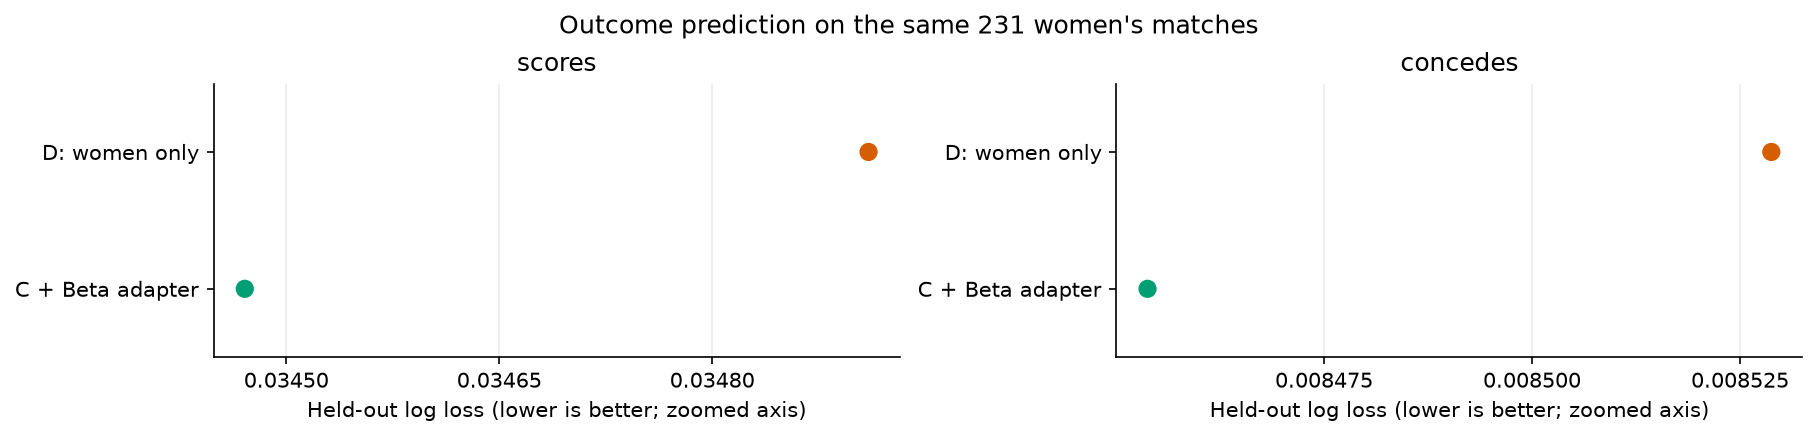

In [4]:
probabilities = {}
metric_rows = []
prediction_checks = []
export_manifest = json.loads((HOME / 'export_manifest.json').read_text(encoding='utf-8'))
saved_metrics = pd.concat([original_metrics, continued_metrics], ignore_index=True)
for model, relative in MODEL_PATHS.items():
    started = time.perf_counter()
    pair = load_pair(HOME, relative)
    signature = {'directory': relative, 'export': checksum(HOME / 'export_manifest.json'),
                 'inputs': checksum(HOME / 'inputs/manifest.json'), 'inference': checksum(HOME / 'inference.py')}
    prediction_path = RESULTS / 'predictions' / f'{model}.npy'
    cache_path = prediction_path.with_suffix('.json')
    cached = json.loads(cache_path.read_text(encoding='utf-8')) if cache_path.exists() else {}
    reuse = prediction_path.exists() and cached.get('signature') == signature
    reuse = reuse and checksum(prediction_path) == cached.get('sha256')
    if reuse:
        predicted = np.load(prediction_path)
    else:
        predicted = predict_pair(pair, features, actions.type_name.to_numpy())
        np.save(prediction_path, predicted)
        cache_path.write_text(json.dumps({'signature': signature, 'sha256': checksum(prediction_path)}, indent=2), encoding='utf-8')
    reference_path = HOME / 'references' / relative / 'test_predictions.npy'
    maximum_difference = None
    if reference_path.exists():
        assert checksum(reference_path) == export_manifest['reference_sha256'][relative]
        reference = np.load(reference_path)
        np.testing.assert_allclose(predicted, reference, rtol=1e-11, atol=1e-13)
        maximum_difference = float(np.max(np.abs(predicted - reference)))
        del reference
    current_metrics = probability_metrics(actions, predicted, model)
    record = catalog.loc[relative]
    original = saved_metrics.loc[(saved_metrics.source == record.source) & (saved_metrics.method == record.method)
                                 & (saved_metrics.budget == record.budget) & (saved_metrics.seed == record.seed)].set_index('target')
    for result in current_metrics:
        np.testing.assert_allclose(result['log_loss'], original.loc[result['target'], 'log_loss'], rtol=1e-10, atol=1e-12)
    probabilities[model] = predicted
    metric_rows.extend(current_metrics)
    prediction_checks.append({'model': model, 'cached': reuse, 'reference_checked': reference_path.exists(),
                              'maximum_prediction_difference': maximum_difference, 'seconds': time.perf_counter() - started})
    print(model, ': 预测和原 test loss 核对通过；', round(time.perf_counter() - started, 2), '秒', flush=True)
    del pair
    gc.collect()
metrics = pd.DataFrame(metric_rows)
metrics.to_csv(RESULTS / 'probability_metrics.csv', index=False)
pd.DataFrame(prediction_checks).to_csv(RESULTS / 'prediction_checks.csv', index=False)
display(metrics.loc[metrics.model.isin(MAIN_MODELS)].pivot(
    index='model', columns='target', values=['log_loss', 'brier', 'roc_auc', 'error_rate_at_05', 'positive_rate', 'always_negative_error_rate']).reindex(MAIN_MODELS))
main_loss = metrics.loc[metrics.model.isin(MAIN_MODELS)].pivot(index='target', columns='model', values='log_loss')
main_loss['adapter_minus_D'] = main_loss['C_adapter'] - main_loss['D']
main_loss['relative_change_percent'] = 100 * main_loss['adapter_minus_D'] / main_loss['D']
main_loss.to_csv(RESULTS / 'main_loss_comparison.csv')
print('负数表示 adapter 的 test loss 更低；这是点估计，不是显著性结论。')
display(main_loss.round(6))
display(Image(filename=str(save_figure(probability_plot(metrics, MAIN_MODELS), FIGURES, '01_probability_accuracy'))))

## 5. 逐场计算完整 Atomic-VAEP 序列
与原 notebook 一样，用 `socceraction.atomic.vaep.formula.value`，不使用普通 VAEP 公式。每场独立处理前一个原子状态、换球权和进球／乌龙球后的重置。

先为所有动作估值，包括门将、进球、零值和负值；再过滤非门将动作做动作分析。球员的 100 动作／45 分钟门槛尚未使用。

In [5]:
valuations = {}
scored_actions = actions.copy()
for model in MODEL_PATHS:
    valuations[model] = atomic_values(actions, probabilities[model])
    for column, target in enumerate(['scores', 'concedes']):
        scored_actions[f'{model}_p_{target}'] = probabilities[model][:, column]
    for component in ['offensive_value', 'defensive_value', 'vaep_value']:
        scored_actions[f'{model}_{component}'] = valuations[model][component].to_numpy()
scored_actions.to_parquet(RESULTS / 'action_values.parquet', index=False)
goalkeepers = set(player_context.loc[player_context.position_bucket.eq('Goalkeeper'), 'player_id'])
non_goalkeeper = ~actions.player_id.isin(goalkeepers)
analysis_actions = actions.loc[non_goalkeeper].reset_index(drop=True)
analysis_values = {model: values.loc[non_goalkeeper].reset_index(drop=True) for model, values in valuations.items()}
print(f'全部 {len(actions):,} 个动作先完成估值；动作类型和空间图使用其中 {len(analysis_actions):,} 个非门将动作。')
del scored_actions
gc.collect();

pair_actions = comparison_actions(analysis_actions, analysis_values, MAIN_LEFT, MAIN_RIGHT)
display(pair_actions[['game_id', 'action_id', 'player_id', 'type_name', 'left_value', 'right_value', 'vaep_delta']].head(10))

全部 669,582 个动作先完成估值；动作类型和空间图使用其中 628,694 个非门将动作。


,game_id,action_id,player_id,type_name,left_value,right_value,vaep_delta
0,3913167,0,4638,pass,0.000000,0.000000,0.000000
1,3913167,1,46972,receival,-0.000130,0.000018,-0.000147
2,3913167,2,46972,dribble,0.000101,0.000541,-0.000440
3,3913167,3,46972,pass,0.001067,0.000850,0.000217
4,3913167,4,31540,interception,0.001144,0.002030,-0.000886
5,3913167,5,31540,pass,0.000182,-0.000162,0.000344
6,3913167,6,31539,receival,0.000242,0.000317,-0.000074
7,3913167,7,31539,pass,-0.000044,0.000245,-0.000288
8,3913167,8,46972,interception,0.000847,0.001199,-0.000352
9,3913167,9,46972,pass,0.000111,0.000196,-0.000085


### 5.1 按动作类型看差异分布
沿用原 notebook 的山脊图：横轴固定为 **−0.01 到 +0.01**，每条分布归一到相同峰高，用来比较形状，不代表动作数量。颜色表示完整分布的平均差，黑点只在均值落入显示范围时出现。

表格统计完整数据；超过横轴范围的动作只是不画出来，仍计入均值、中位数、标准差和总差。进球、接球、拦截、出界等原子类型保持独立。图只画至少 500 条动作的类型。

,type_name,actions,total_delta,mean_delta,median_delta,std_delta,mean_abs_delta,p95_abs_delta,left_mean,right_mean,offensive_delta,defensive_delta,outside_display,left,right,shown_in_distribution
21,yellow_card,526,-2.070378,-0.003936,-0.001387,0.041704,0.017473,0.080204,-0.003662,0.000274,-0.001051,-0.002885,191,C_adapter,D,True
7,goal,676,-33.405422,-0.049416,-0.037904,0.129729,0.103040,0.290324,0.572887,0.622303,-0.049570,0.000153,623,C_adapter,D,True
10,offside,864,-3.071652,-0.003555,-0.002224,0.014036,0.008081,0.029017,-0.019683,-0.016128,-0.003550,-0.000005,198,C_adapter,D,True
2,corner,2178,-5.283834,-0.002426,-0.001547,0.027007,0.014946,0.046514,0.008739,0.011165,-0.002434,0.000008,1021,C_adapter,D,True
6,freekick,4463,-3.392953,-0.000760,-0.000068,0.022925,0.007895,0.035384,-0.001121,-0.000361,-0.000318,-0.000443,737,C_adapter,D,True
3,cross,5023,-0.030948,-0.000006,0.000256,0.022707,0.013537,0.044029,0.013996,0.014002,0.000023,-0.000029,2080,C_adapter,D,True
5,foul,5175,-5.267835,-0.001018,-0.000073,0.026031,0.009384,0.043543,-0.018378,-0.017360,-0.000304,-0.000714,1013,C_adapter,D,True
16,shot,5734,8.875281,0.001548,-0.004270,0.079117,0.048266,0.181845,0.046363,0.044815,0.001695,-0.000147,4233,C_adapter,D,True
19,take_on,7333,6.297137,0.000859,0.000615,0.015364,0.006446,0.024742,-0.000250,-0.001108,0.000819,0.000040,1160,C_adapter,D,True
0,bad_touch,8053,-27.025373,-0.003356,-0.001048,0.022044,0.007168,0.025937,-0.014989,-0.011633,-0.001857,-0.001499,1211,C_adapter,D,True


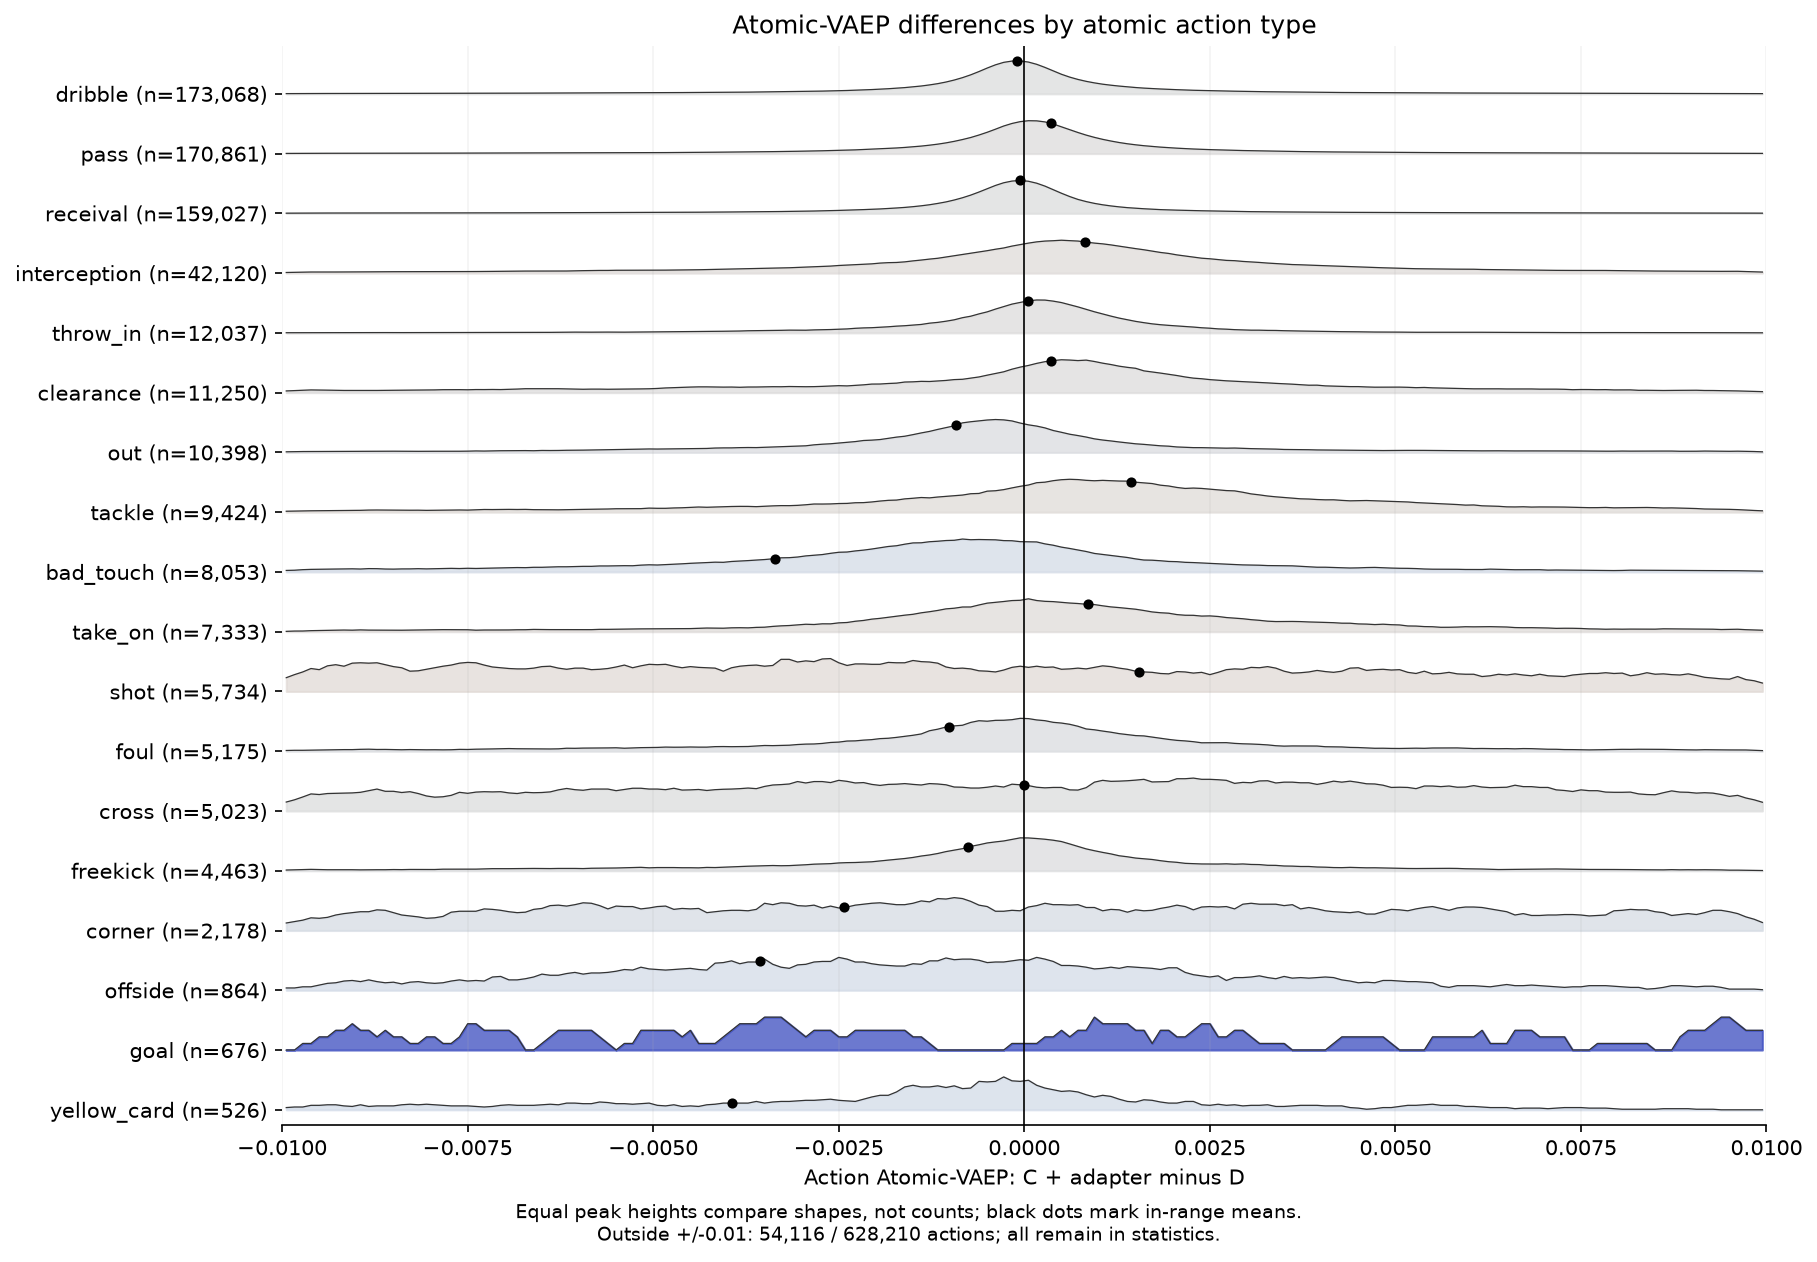

In [6]:
action_differences = distribution_summary(pair_actions, ['type_name'], ACTION_DELTA_LIMIT)
action_differences['left'], action_differences['right'] = MAIN_LEFT, MAIN_RIGHT
action_differences['shown_in_distribution'] = action_differences.actions.ge(MIN_TYPE_ACTIONS)
action_differences.to_csv(RESULTS / 'action_type_differences.csv', index=False)
action_plot_summary = action_differences.loc[action_differences.shown_in_distribution].sort_values('actions')
display(action_plot_summary.round(6))
display(Image(filename=str(save_figure(action_distribution_plot(
    pair_actions, action_plot_summary, 'type_name', MAIN_PAIRS[0], 'Atomic-VAEP differences by atomic action type',
    ACTION_DELTA_LIMIT), FIGURES, '02_action_type_distributions'))))

#### 5.1.1 传球类型 × 原始传球高度
沿用原 notebook 的事件匹配：用比赛 ID 和原始事件 ID 连接本包的传球高度快照。只保留原始事件为 Pass 的 pass、cross、throw_in、freekick、corner、goalkick；freekick 中的直接任意球射门排除，接球／拦截／出界等结果原子不重复计作传球。

Ground、Low、High、Unknown 均保留；没有成功动作筛选，也没有球员出场门槛。高度只用于解释现有给分差异，不是新模型输入。所有实际存在的类型×高度组合进表，至少 500 条才画分布。

通过原始事件匹配的传球原子： 194798 ；未知高度： 0
排除的直接任意球射门原子： 179


,type_name,pass_height,actions,total_delta,mean_delta,median_delta,std_delta,mean_abs_delta,p95_abs_delta,left_mean,right_mean,offensive_delta,defensive_delta,outside_display,shown_in_distribution
0,pass,Ground Pass,124126,44.901600,0.000362,0.000119,0.006882,0.002332,0.009092,0.000289,-0.000073,0.000256,0.000106,5502,True
1,pass,Low Pass,19390,7.280295,0.000375,0.000062,0.008718,0.003099,0.012185,0.001004,0.000628,0.000305,0.000070,1246,True
2,pass,High Pass,27345,9.269240,0.000339,0.000237,0.007534,0.002988,0.010907,0.003523,0.003184,0.000215,0.000124,1551,True
3,cross,Ground Pass,794,1.305558,0.001644,0.002394,0.033583,0.021327,0.067204,0.014714,0.013070,0.001660,-0.000016,478,True
4,cross,Low Pass,793,1.409802,0.001778,0.001205,0.025005,0.016077,0.054588,0.015211,0.013433,0.001802,-0.000024,379,True
5,cross,High Pass,3436,-2.746308,-0.000799,-0.000094,0.018636,0.011151,0.035512,0.013549,0.014348,-0.000766,-0.000034,1223,True
6,throw_in,Low Pass,7267,0.892154,0.000123,0.000181,0.003751,0.001649,0.005697,0.001172,0.001049,-0.000113,0.000236,127,True
7,throw_in,High Pass,4770,-0.214781,-0.000045,0.000167,0.003808,0.001765,0.005819,0.002591,0.002636,-0.000355,0.000310,92,True
8,freekick,Ground Pass,2371,-1.335735,-0.000563,-0.000081,0.011964,0.003433,0.012967,-0.002957,-0.002393,0.000124,-0.000687,154,True
9,freekick,Low Pass,70,0.167107,0.002387,-0.000223,0.021569,0.009510,0.044490,-0.003520,-0.005907,0.002847,-0.000460,18,False


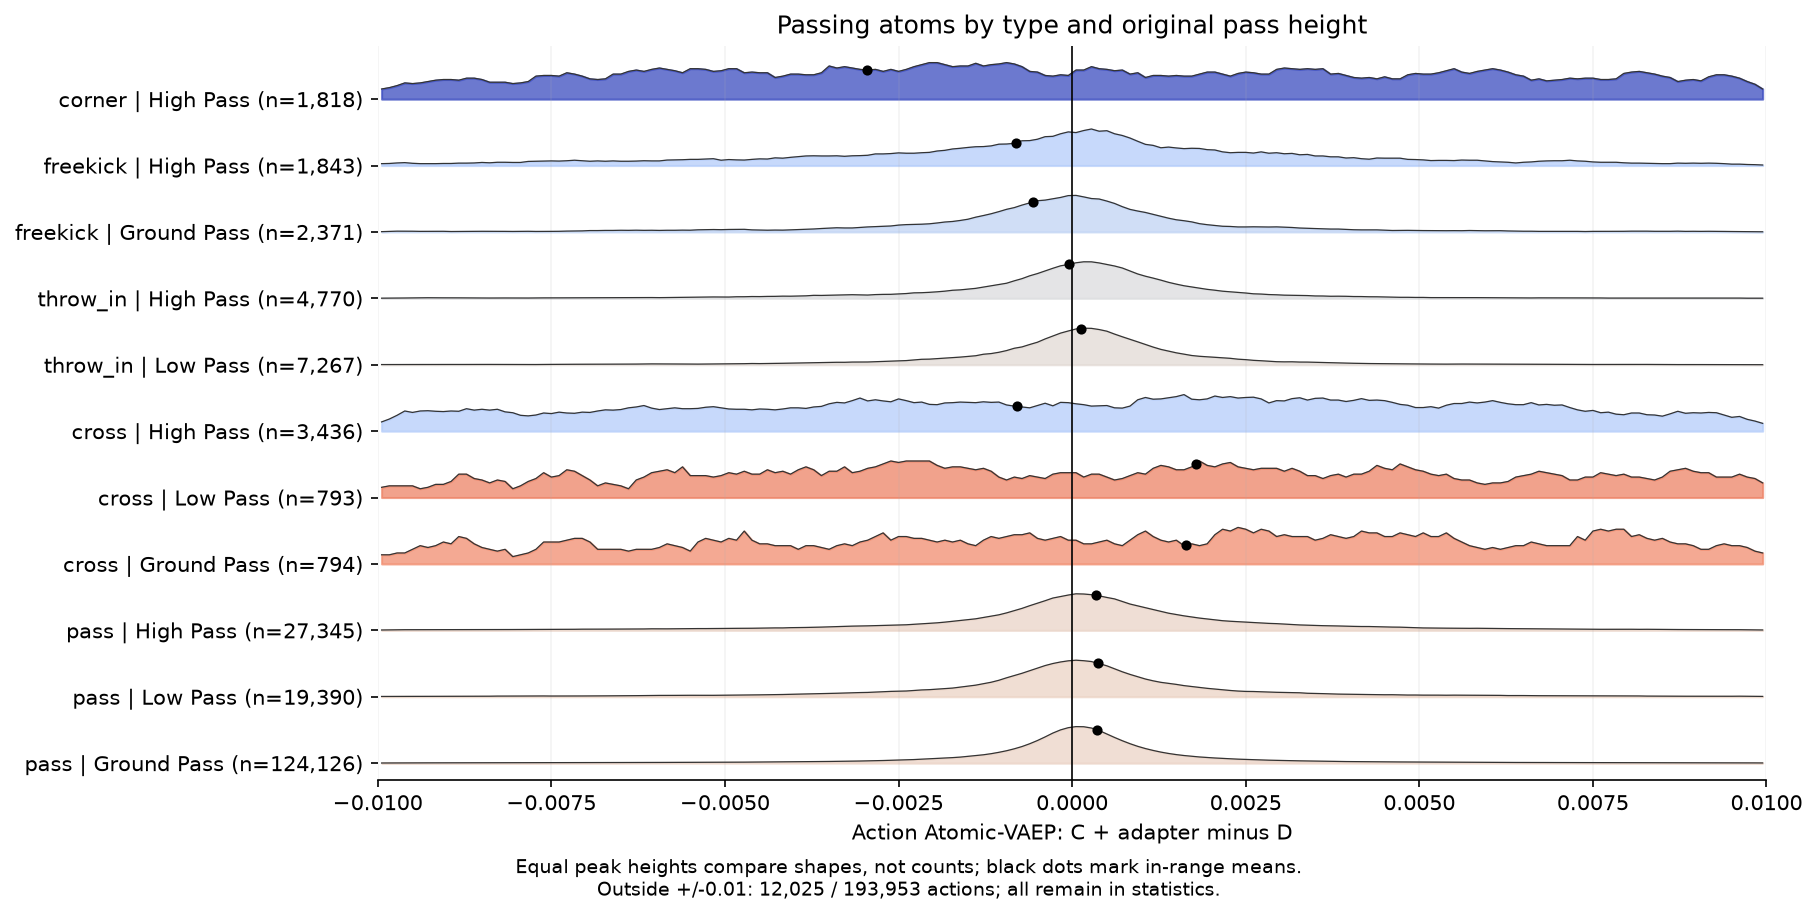

In [7]:
height_events = pd.read_parquet(HOME / 'inputs/pass_height_events.parquet')
pass_actions = attach_pass_heights(pair_actions, height_events)
pass_height_summary = distribution_summary(pass_actions, ['type_name', 'pass_height'], ACTION_DELTA_LIMIT)
pass_height_summary['shown_in_distribution'] = pass_height_summary.actions.ge(MIN_TYPE_ACTIONS)
pass_height_summary.to_csv(RESULTS / 'pass_height_differences.csv', index=False)
print('通过原始事件匹配的传球原子：', len(pass_actions), '；未知高度：', int(pass_actions.pass_height.eq('Unknown').sum()))
candidate_count = pair_actions.type_name.isin(['pass', 'cross', 'throw_in', 'freekick', 'corner', 'goalkick']).sum()
print('排除的直接任意球射门原子：', int(candidate_count - len(pass_actions)))
display(pass_height_summary.round(6))
pass_actions['type_height'] = pass_actions.type_name.astype(str) + ' | ' + pass_actions.pass_height.astype(str)
pass_plot_summary = pass_height_summary.loc[pass_height_summary.shown_in_distribution].copy()
pass_plot_summary['type_height'] = pass_plot_summary.type_name.astype(str) + ' | ' + pass_plot_summary.pass_height.astype(str)
display(Image(filename=str(save_figure(action_distribution_plot(
    pass_actions, pass_plot_summary, 'type_height', MAIN_PAIRS[0], 'Passing atoms by type and original pass height',
    ACTION_DELTA_LIMIT), FIGURES, '03_pass_height_distributions'))))

### 5.2 把六类动作的差异放回球场
与原 notebook 一样展示 **shot、pass、receival、dribble、cross、take_on** 六个面板，使用 12×16 网格。射门格至少 10 条动作，其他类型至少 20 条；空白不是零。

与原 enriched Atomic-VAEP notebook 共用固定色标 **[-0.03, 0.03]** 和 `coolwarm` 配色（透明度 0.86），不再各自按分位数缩放。同样的颜色表示同样大小的平均 VAEP 差值。超出范围只让颜色饱和，CSV 数值和球员贡献不截断。红色为 adapter 给分更高，蓝色为 D 给分更高。每个动作按所属球队向右进攻：传球／过人／带球是起点，接球是接球点，射门是射门点。take_on 包括尝试过掉对手的成功和失败动作，与带球移动 dribble 分开。

,type_name,row,column,actions,total_delta,mean_delta,median_delta,left_mean,right_mean,left,right,minimum_actions
831,cross,3,15,339,1.690305,0.004986,0.005509,0.020258,0.015272,C_adapter,D,20
911,cross,8,15,307,2.473692,0.008058,0.004257,0.014741,0.006683,C_adapter,D,20
798,cross,1,14,292,-0.494197,-0.001692,-0.002515,0.013438,0.015131,C_adapter,D,20
815,cross,2,15,247,0.873012,0.003534,0.002055,0.011137,0.007602,C_adapter,D,20
799,cross,1,15,240,1.045797,0.004357,0.003697,0.013813,0.009455,C_adapter,D,20
942,cross,10,14,233,-1.115785,-0.004789,-0.003817,0.014035,0.018824,C_adapter,D,20
926,cross,9,14,227,-0.919376,-0.004050,-0.002855,0.017111,0.021161,C_adapter,D,20
797,cross,1,13,211,-1.387630,-0.006576,-0.005555,0.013666,0.020242,C_adapter,D,20
814,cross,2,14,209,0.279478,0.001337,0.001416,0.016832,0.015495,C_adapter,D,20
943,cross,10,15,185,0.107347,0.000580,-0.000119,0.009135,0.008555,C_adapter,D,20


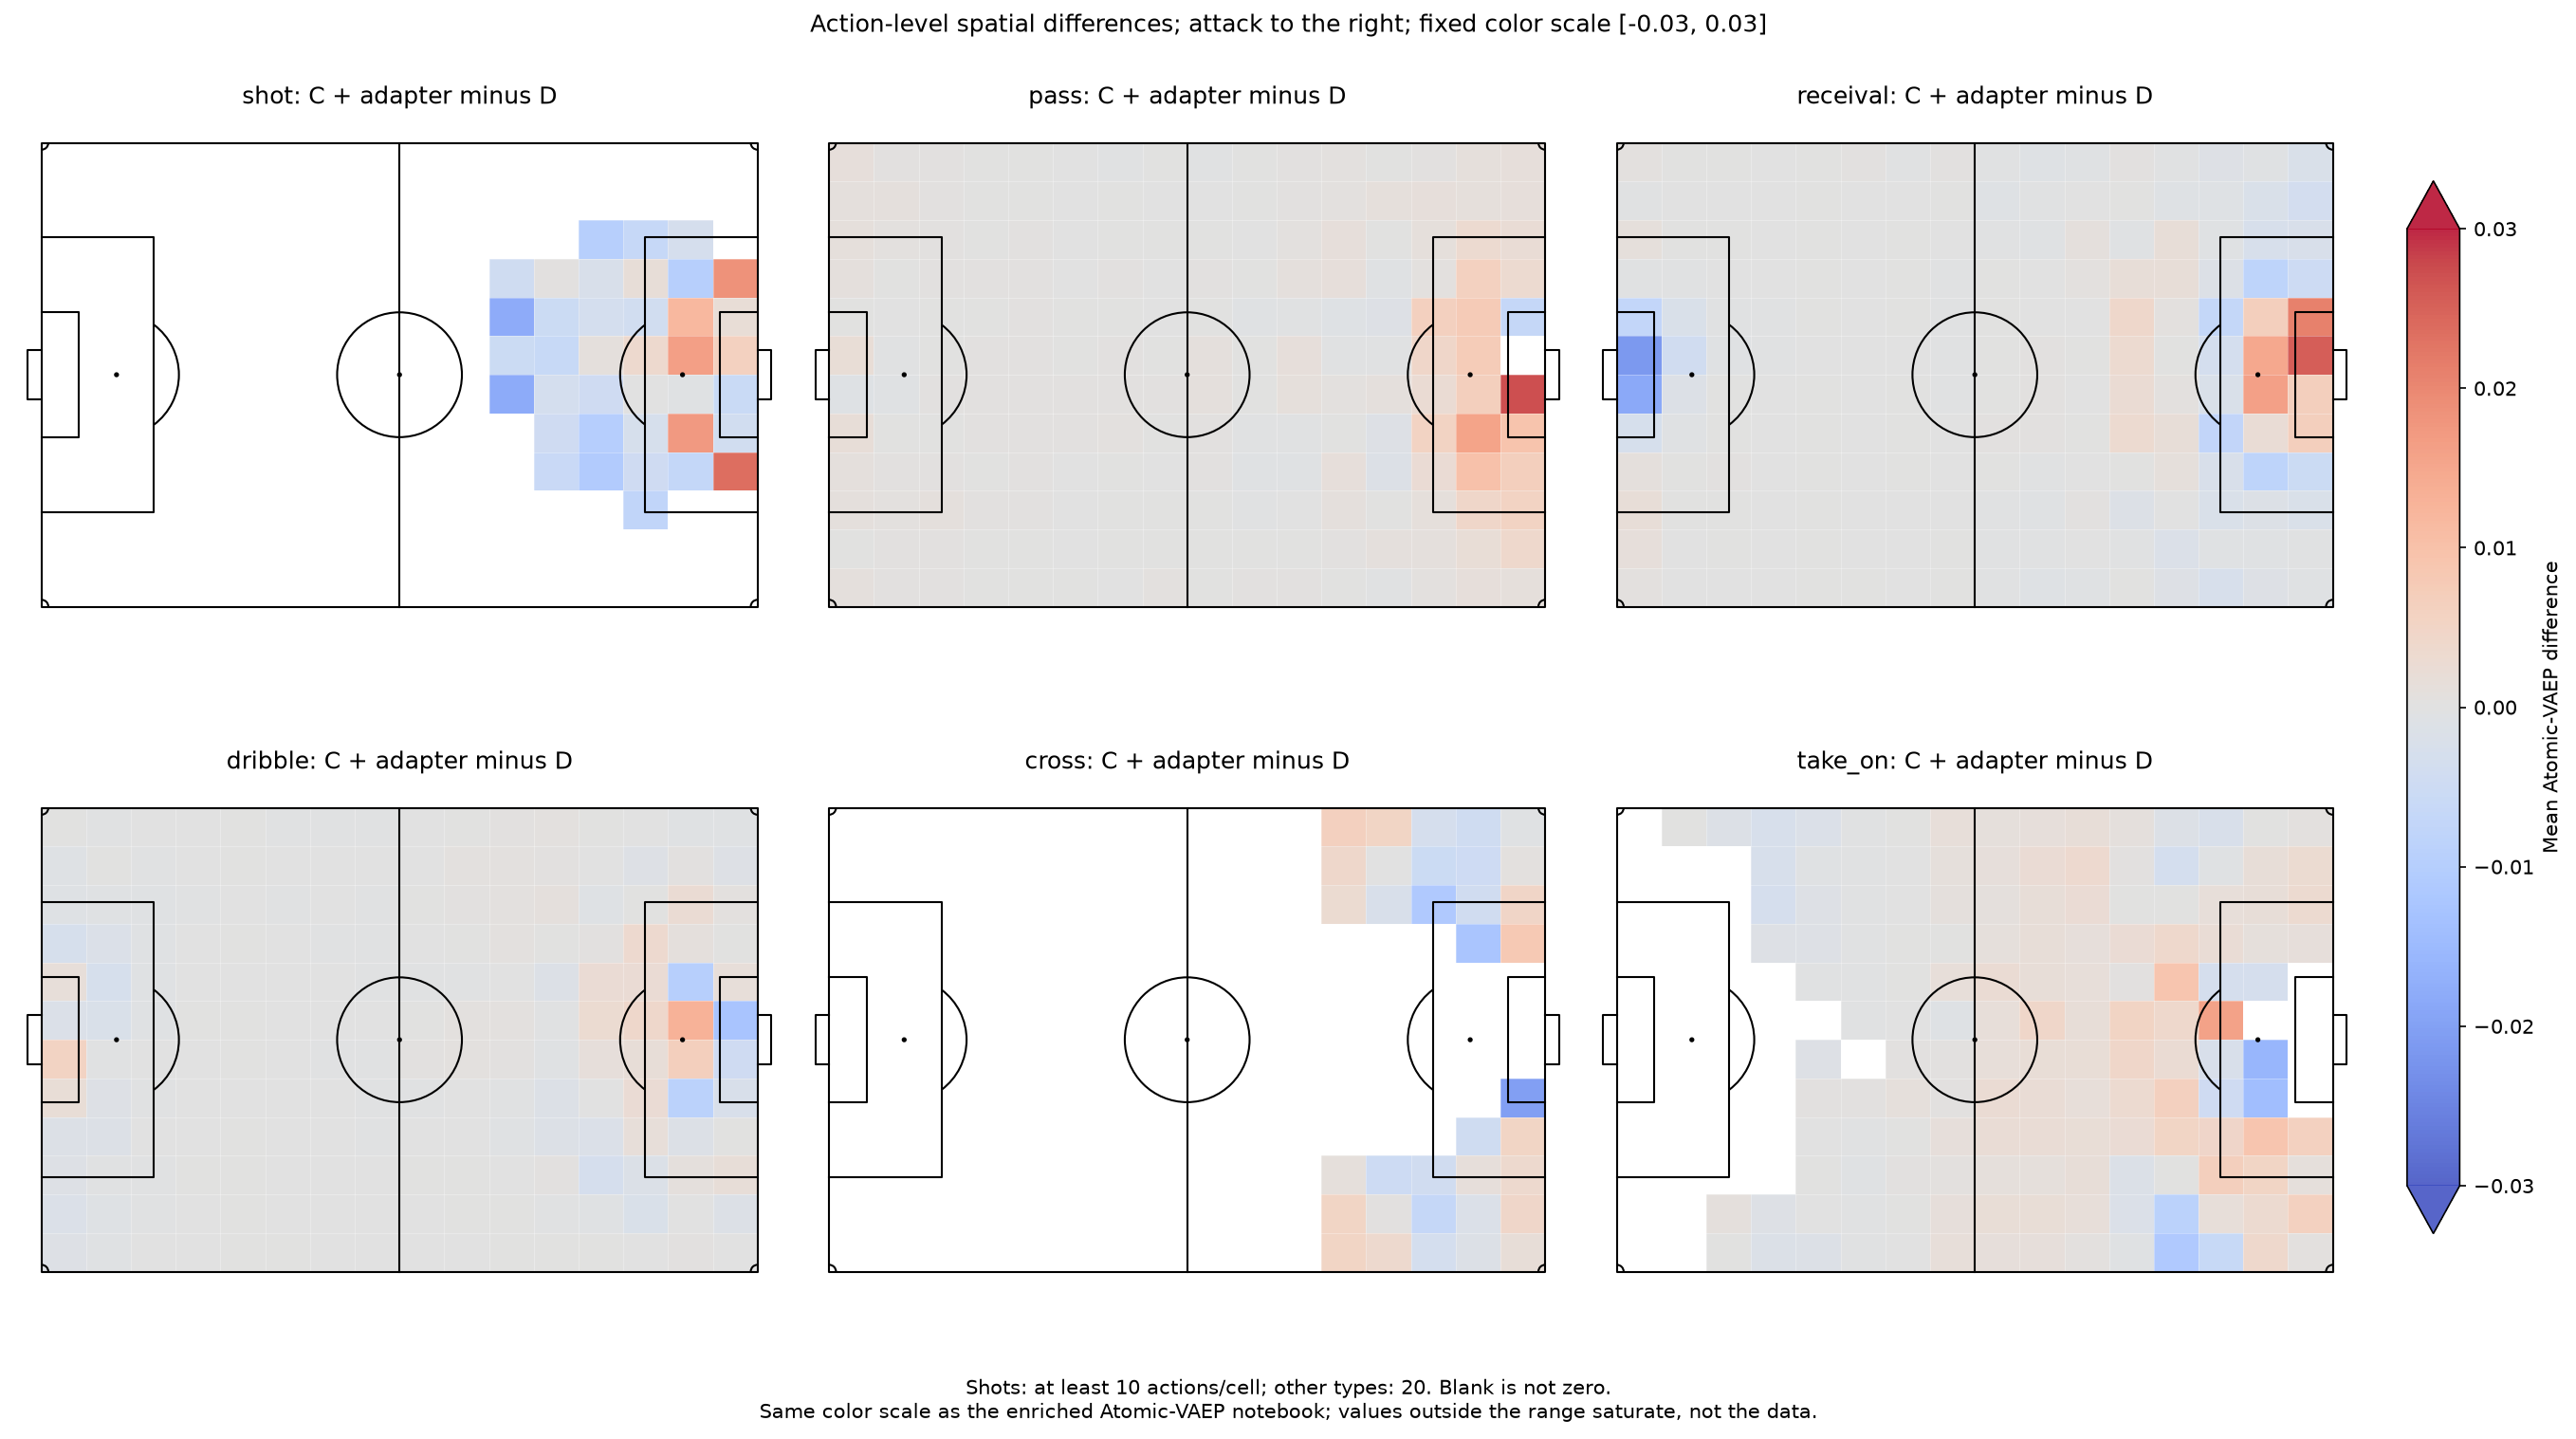

In [8]:
spatial_differences = spatial_summary(analysis_actions, analysis_values, MAIN_PAIRS)
spatial_differences.to_csv(RESULTS / 'spatial_differences.csv', index=False)
display(spatial_differences.loc[spatial_differences.actions.gt(0)].sort_values(
    ['type_name', 'actions'], ascending=[True, False]).head(30).round(6))
display(Image(filename=str(save_figure(spatial_plot(spatial_differences, MAIN_PAIRS, color_limit=SPATIAL_COLOR_LIMIT), FIGURES, '04_spatial_differences'))))

## 6. 球员总贡献：先确定唯一的分析群体
累加同一球员的全部测试动作，包括失败、零值和负值，再按 player_id 连接位置与完整测试出场时间。保留非门将、至少 100 个动作、至少 45 分钟的球员。此后总分、每90分钟、位置分析、Top 15 都用这个群体，不再换筛选标准。

排名与原 notebook 一致：分数降序，`method='min'` 处理同分。主指标为 Spearman、Kendall tau-b、平均绝对名次差除以 `人数−1`；另列原始名次差、完全一致／相差不超过2或5名的比例和 Top 10。Top 10 在人数不超过10或边界同分扩张名单时不报告比例。

In [9]:
all_players, players = player_values(actions, valuations, player_context, MIN_ACTIONS, MIN_MINUTES)
all_players.to_csv(RESULTS / 'all_player_totals.csv', index=False)
players.to_csv(RESULTS / 'player_values.csv', index=False)
display(players.groupby('position_bucket').agg(players=('player_id', 'size'), minutes=('test_minutes', 'sum')))
main_total_summary = ranking_summary(players, [MAIN_LEFT, MAIN_RIGHT], 'total', RANK_TOP_K)
main_total_summary.to_csv(RESULTS / 'total_ranking_summary.csv', index=False)

def show_ranking_summary(summary):
    primary = ['position', 'players', 'spearman', 'kendall_tau_b', 'mean_abs_rank_change_fraction']
    print('主指标：相关性越高、归一化名次差越小，表示排名越接近。')
    display(summary[primary].round(4))
    print('其他诊断：固定名次范围及 Top 10 受群体人数影响。')
    display(summary.drop(columns=['spearman', 'kendall_tau_b', 'mean_abs_rank_change_fraction']).round(4))

show_ranking_summary(main_total_summary.loc[main_total_summary.position == 'All eligible'])

,players,minutes
position_bucket,,
Attacking Midfield,63,25048.295317
Center Back,211,102273.146300
Central Midfield,83,33691.063700
Defensive Midfield,168,68297.384933
Forward,147,58969.802950
Fullback / Wing Back,224,95068.581250
Wide Midfielder / Winger,163,60398.558117


主指标：相关性越高、归一化名次差越小，表示排名越接近。


,position,players,spearman,kendall_tau_b,mean_abs_rank_change_fraction
0,All eligible,1059,0.9802,0.8828,0.0405


其他诊断：固定名次范围及 Top 10 受群体人数影响。


,measure,position,left,right,players,scored_actions,mean_abs_rank_change,exact_rank_agreement_pct,within_2_rank_agreement_pct,within_5_rank_agreement_pct,mean_value_difference,median_value_difference,mean_abs_value_difference,top_k,top_overlap,top_overlap_fraction,boundary_tie,shortlist_is_entire_group
0,total,All eligible,C_adapter,D,1059,618711,42.882,1.1331,6.3267,12.9367,0.0091,0.0051,0.1571,10,8,0.8,False,False


### 6.1 总贡献散点图
两轴是贡献分，不是名次；虚线表示给分相同。保留负分，标出绝对给分差最大的八名球员，方便回到具体案例。

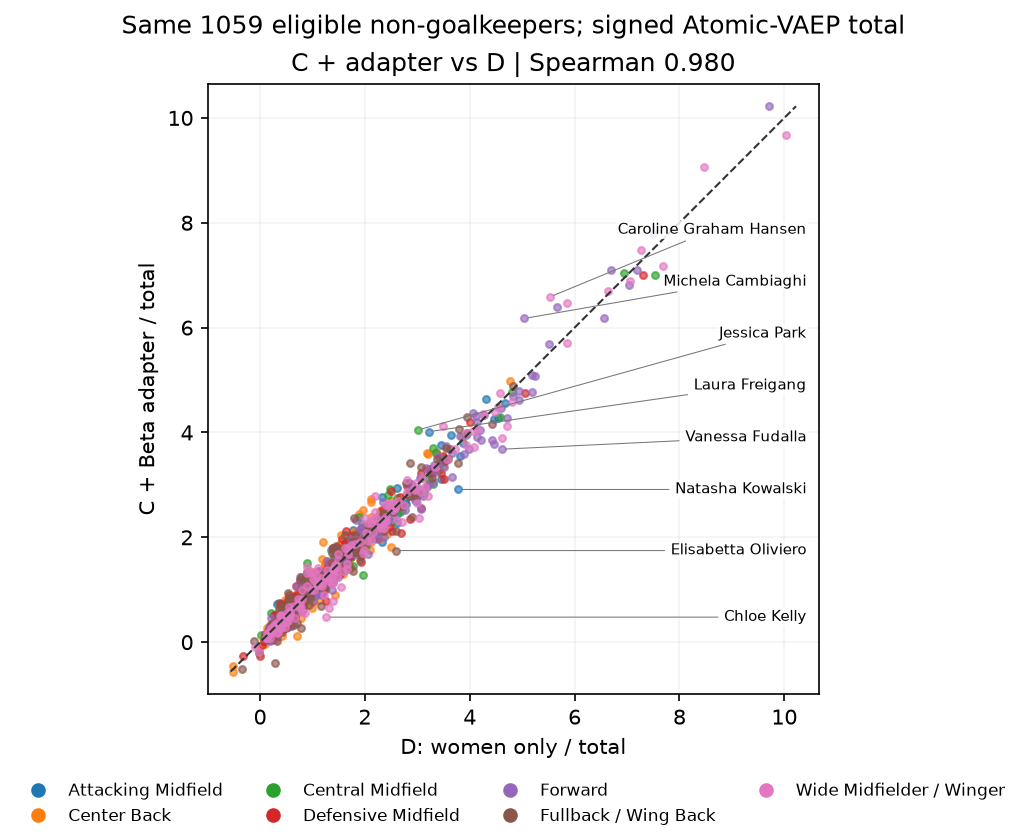

In [10]:
display(Image(filename=str(save_figure(player_plot(players, MAIN_PAIRS, 'total', annotate=True), FIGURES, '05_total_overall_scatter'))))

### 6.2 在每个完整位置组内比较总贡献排名
仍用同一批球员，但在各完整位置组内重新排名。主指标与总体一致；不能把不同人数的位置组的原始名次差直接当作可比尺度。

In [11]:
show_ranking_summary(main_total_summary.loc[main_total_summary.position != 'All eligible'].sort_values('players', ascending=False))

主指标：相关性越高、归一化名次差越小，表示排名越接近。


,position,players,spearman,kendall_tau_b,mean_abs_rank_change_fraction
6,Fullback / Wing Back,224,0.9681,0.8547,0.0519
2,Center Back,211,0.9671,0.8475,0.0549
4,Defensive Midfield,168,0.9779,0.8752,0.0458
7,Wide Midfielder / Winger,163,0.9793,0.8909,0.0386
5,Forward,147,0.9909,0.9189,0.0298
3,Central Midfield,83,0.9807,0.8930,0.0408
1,Attacking Midfield,63,0.9753,0.8730,0.0497


其他诊断：固定名次范围及 Top 10 受群体人数影响。


,measure,position,left,right,players,scored_actions,mean_abs_rank_change,exact_rank_agreement_pct,within_2_rank_agreement_pct,within_5_rank_agreement_pct,mean_value_difference,median_value_difference,mean_abs_value_difference,top_k,top_overlap,top_overlap_fraction,boundary_tie,shortlist_is_entire_group
6,total,Fullback / Wing Back,C_adapter,D,224,142313,11.5804,4.9107,20.0893,38.8393,0.0135,0.0110,0.1450,10,9,0.9,False,False
2,total,Center Back,C_adapter,D,211,163669,11.5261,6.6351,18.0095,33.6493,0.0435,0.0339,0.1514,10,10,1.0,False,False
4,total,Defensive Midfield,C_adapter,D,168,101811,7.6548,6.5476,22.6190,50.5952,0.0058,0.0031,0.1372,10,9,0.9,False,False
7,total,Wide Midfielder / Winger,C_adapter,D,163,72065,6.2577,6.1350,35.5828,60.7362,-0.0226,-0.0174,0.1656,10,9,0.9,False,False
5,total,Forward,C_adapter,D,147,58583,4.3537,9.5238,40.8163,70.0680,-0.0228,-0.0257,0.1824,10,9,0.9,False,False
3,total,Central Midfield,C_adapter,D,83,46795,3.3494,7.2289,55.4217,81.9277,0.0159,-0.0132,0.1632,10,8,0.8,False,False
1,total,Attacking Midfield,C_adapter,D,63,33475,3.0794,11.1111,50.7937,82.5397,0.0351,0.0215,0.1837,10,8,0.8,False,False


### 6.3 总贡献的位置图：相关性、分布、名次变化、散点
沿用原 notebook 的四类图。相关性条从零起画，负值／未定义值仍以文字显示。位置差异分布显示合并分布的中央96%范围加留白，各条同峰高；统计不截断。

名次变化热图每列对应一个整数，范围 −10 到 +10；超范围者不挤到边界，逐位置标出人数。总分和每90分钟热图共用绝对人数色标。各位置散点共用轴范围。

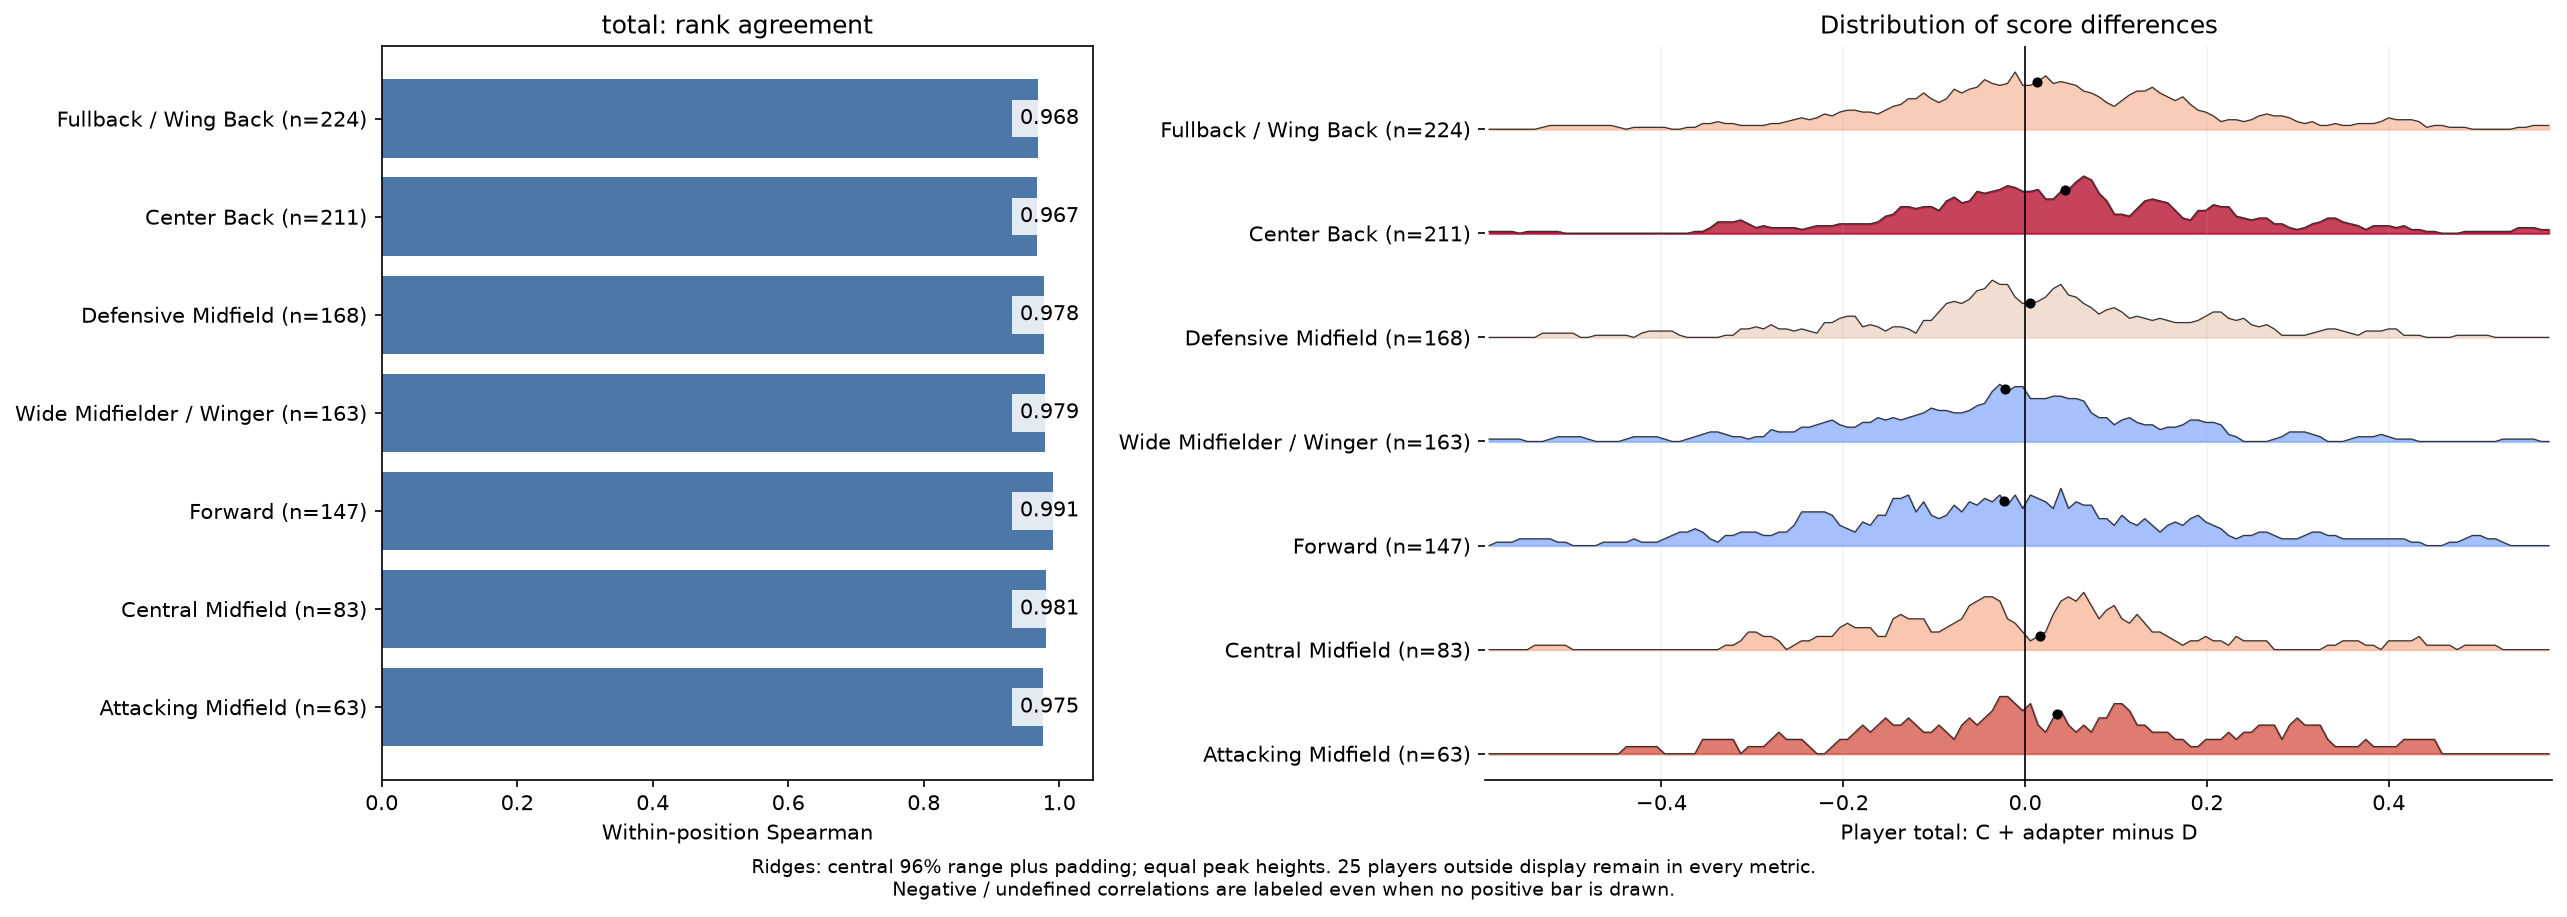

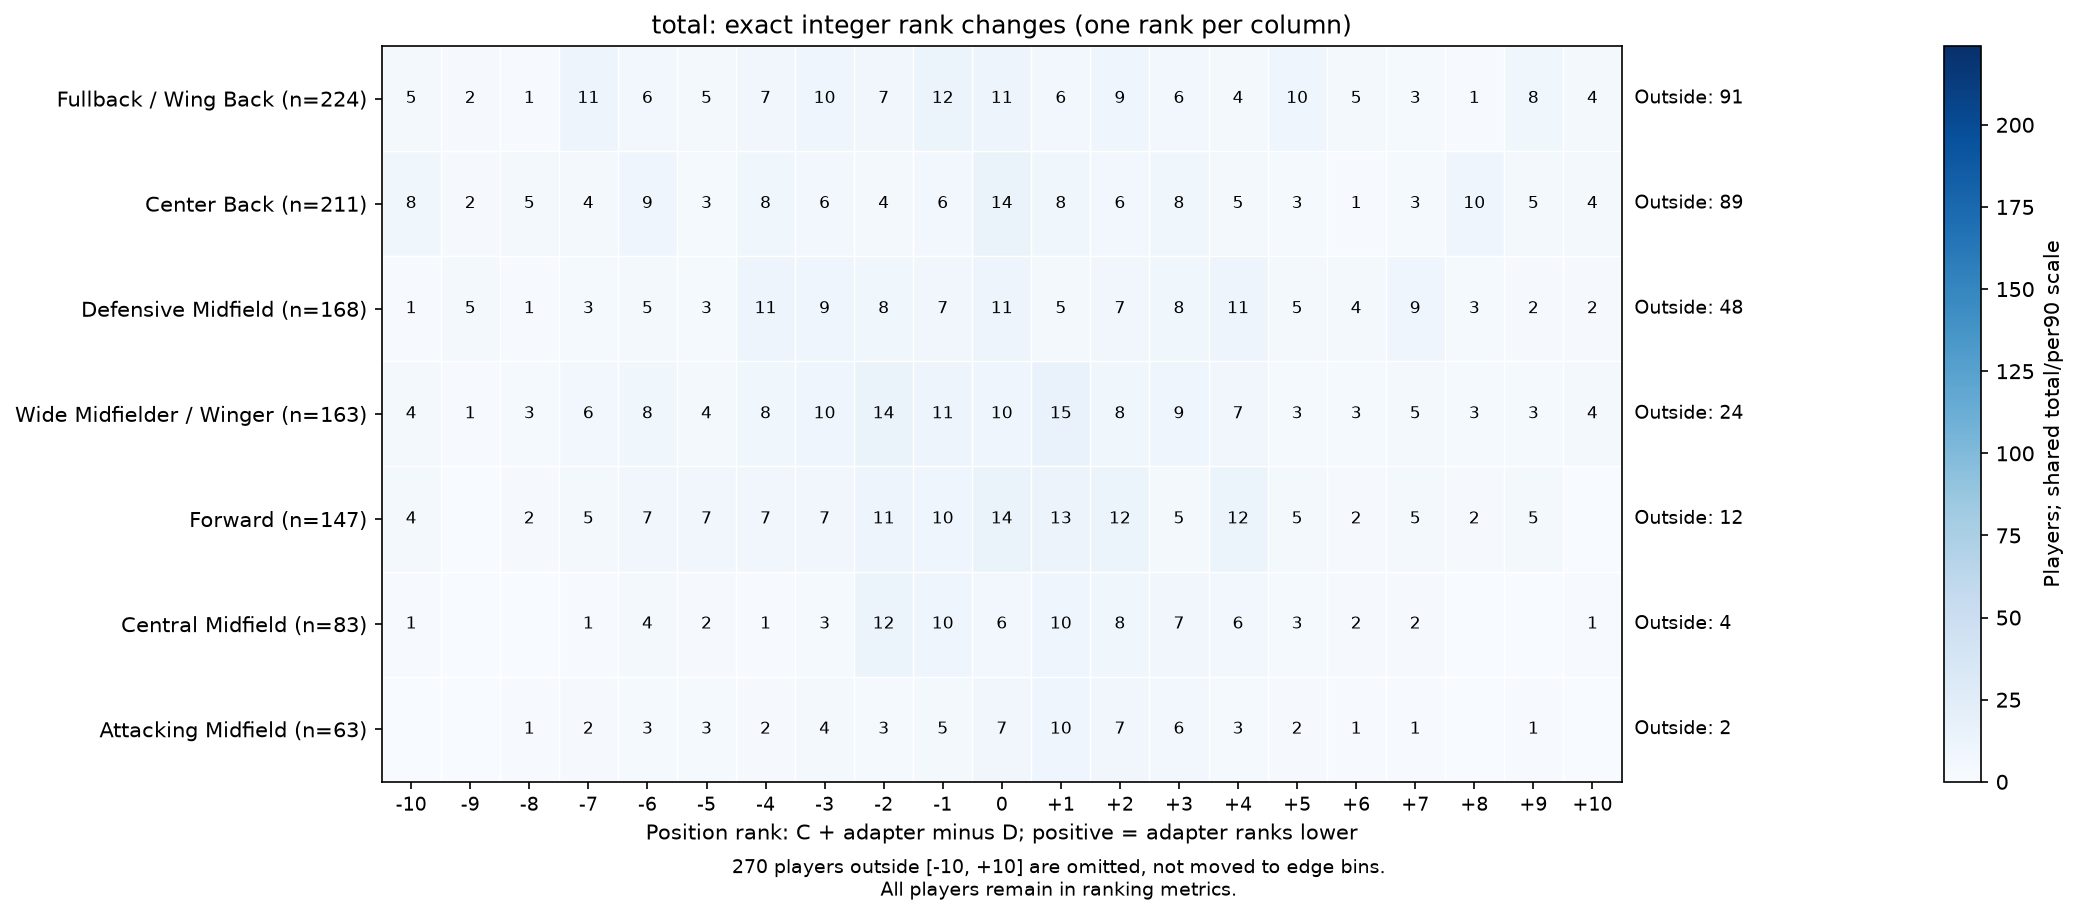

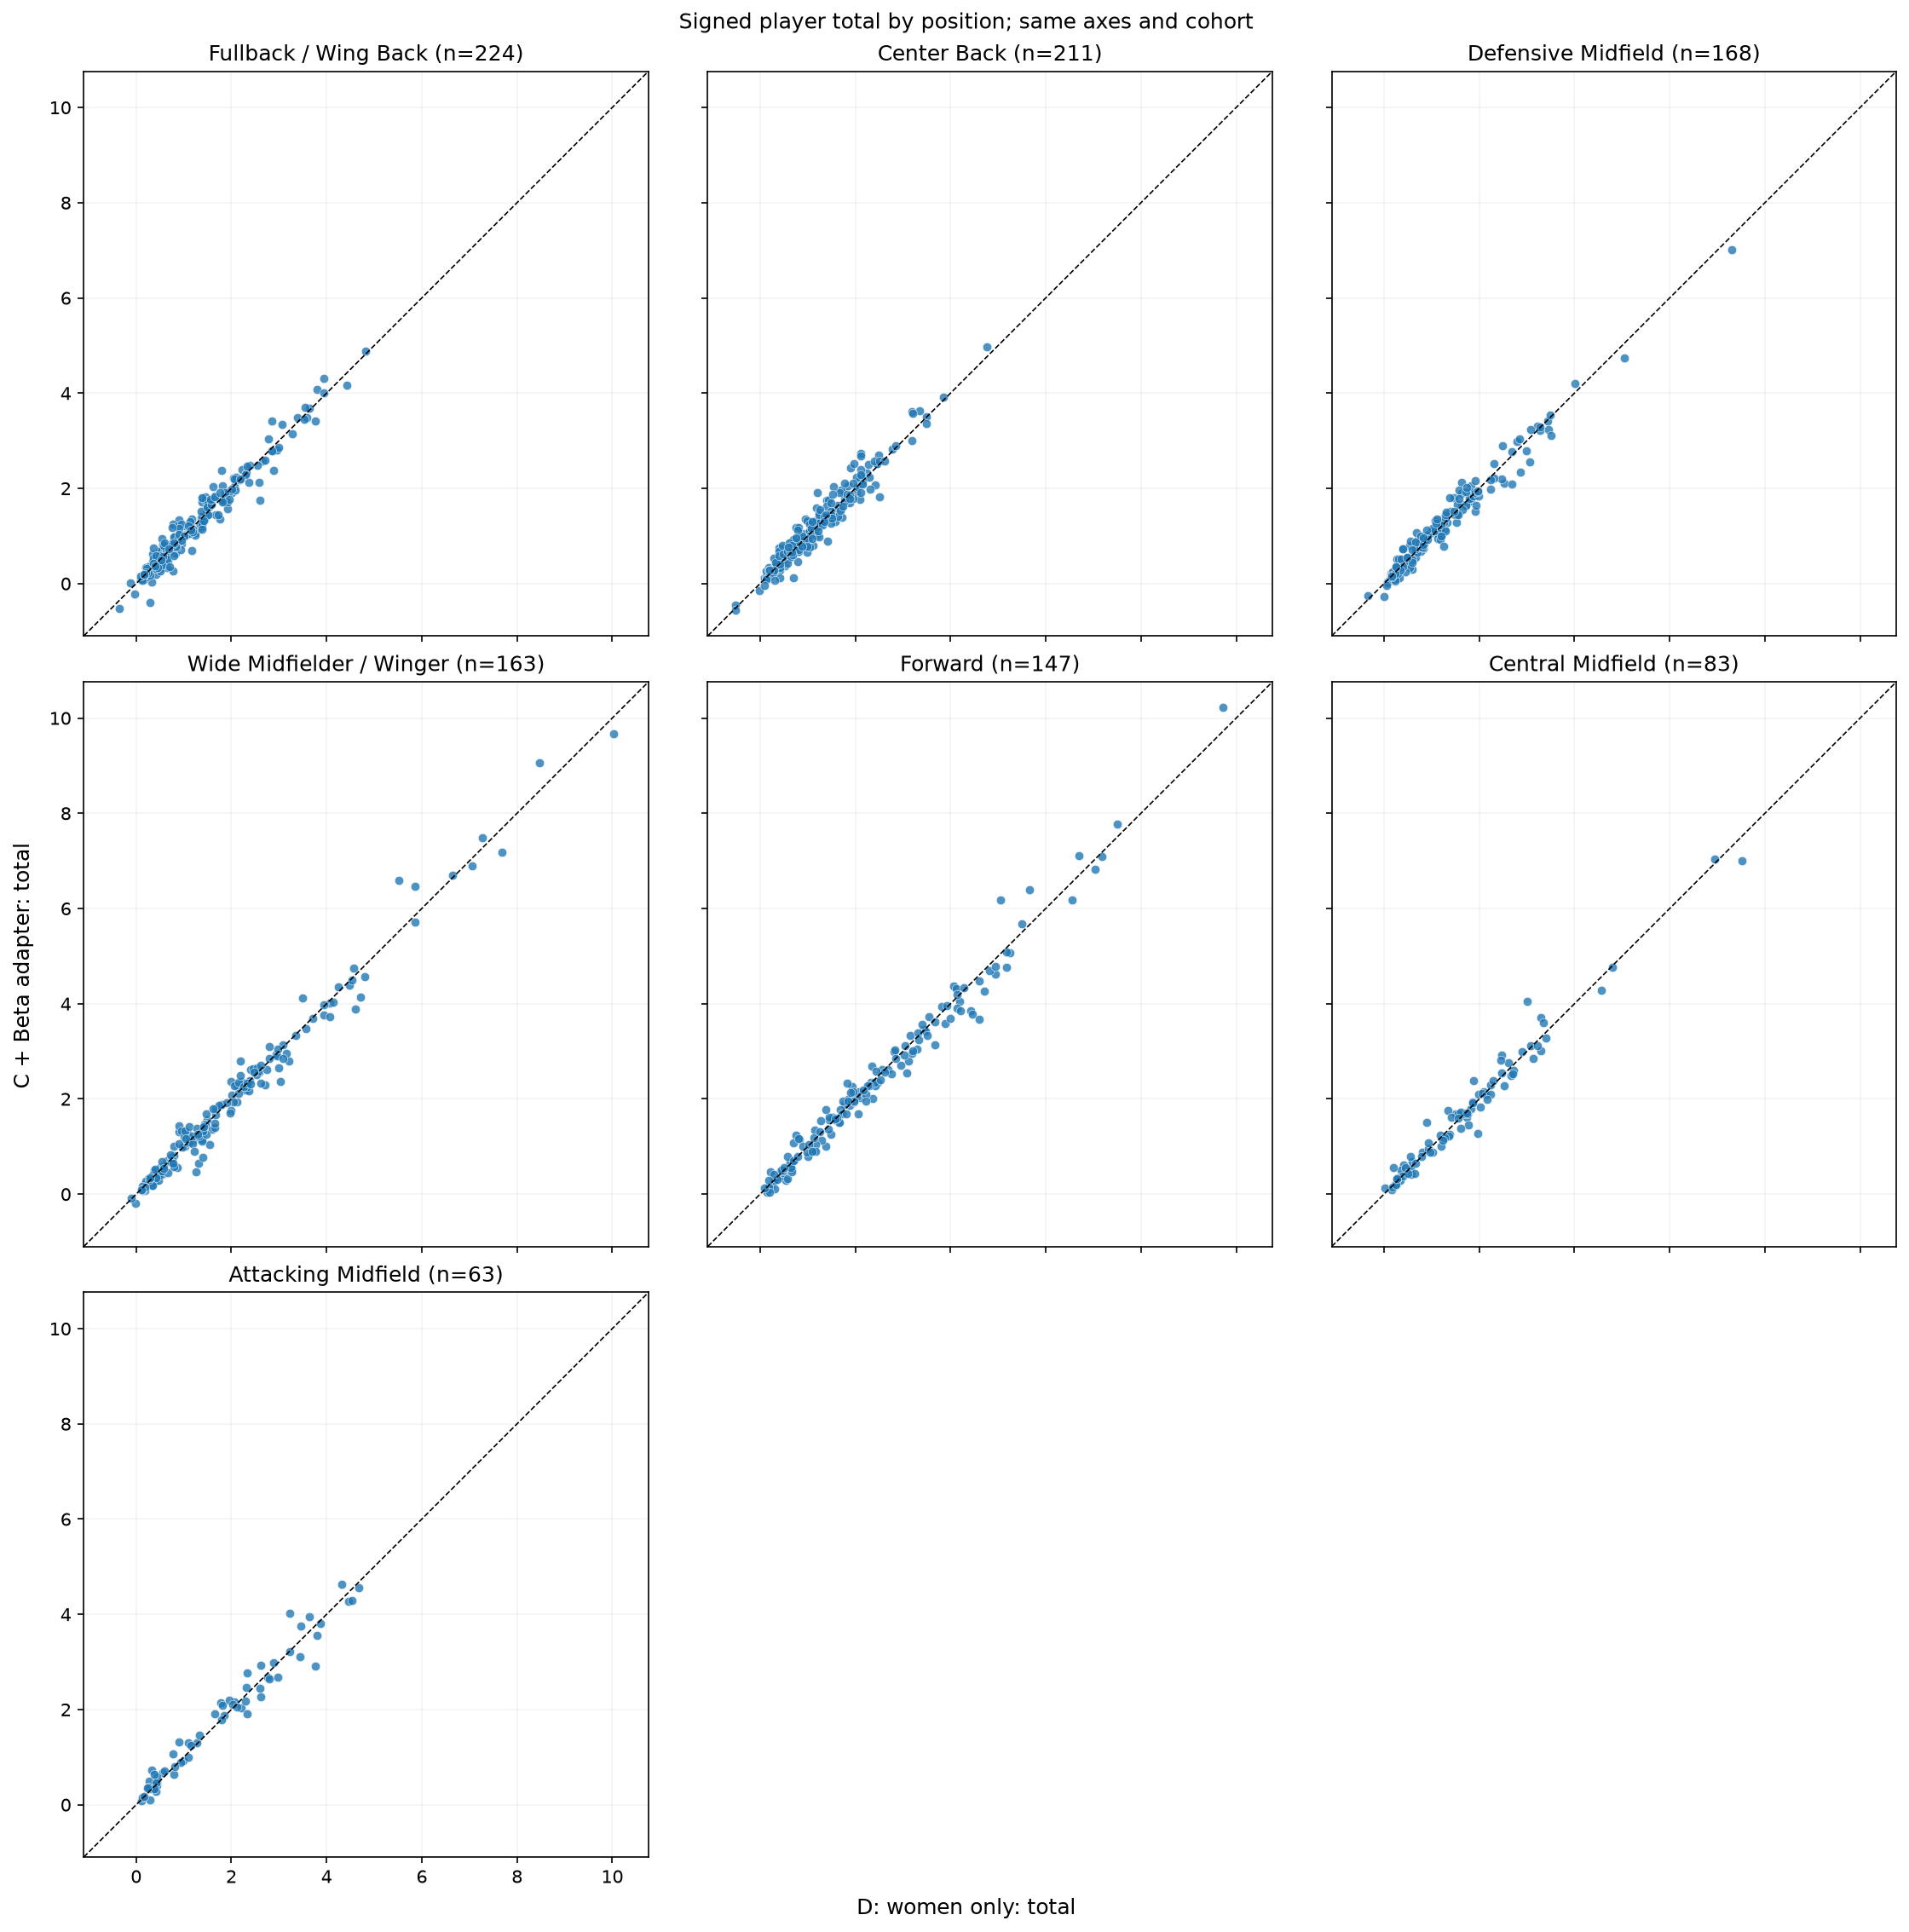

In [12]:
position_order = players.groupby('position_bucket').size().sort_values(ascending=False)
rank_color_max = RANK_MOVEMENT_COLOR_MAX
total_movement = rank_movement_counts(players, MAIN_LEFT, MAIN_RIGHT, 'total', RANK_MOVEMENT_LIMIT)
total_movement.to_csv(RESULTS / 'total_rank_movement_counts.csv', index=False)
display(Image(filename=str(save_figure(position_distribution_plot(players, main_total_summary, MAIN_PAIRS[0], 'total'), FIGURES, '06_total_position_distributions'))))
display(Image(filename=str(save_figure(rank_movement_plot(total_movement, MAIN_PAIRS[0], 'total', rank_color_max), FIGURES, '07_total_rank_movement'))))
display(Image(filename=str(save_figure(position_scatter_plot(players, MAIN_PAIRS[0], 'total'), FIGURES, '08_total_position_scatter'))))

## 7. 每90分钟贡献：同一群体、同一分母
`每90分钟 = 全部测试动作的贡献总和 / 全部测试出场分钟 × 90`。包括有出场但没有原子动作的比赛，不是控球时间，也不是先算逐场平均。

直接复用第6节球员，不增加任何筛选；总分与每90分钟的球员 ID 必须完全相同。低出场时间球员仍可能不稳定。

In [13]:
for model in MODEL_PATHS:
    np.testing.assert_allclose(players[f'{model}_per90'], players[f'{model}_total'] / players.test_minutes * 90)
main_per90_summary = ranking_summary(players, [MAIN_LEFT, MAIN_RIGHT], 'per90', RANK_TOP_K)
main_per90_summary.to_csv(RESULTS / 'per90_ranking_summary.csv', index=False)
show_ranking_summary(main_per90_summary.loc[main_per90_summary.position == 'All eligible'])

主指标：相关性越高、归一化名次差越小，表示排名越接近。


,position,players,spearman,kendall_tau_b,mean_abs_rank_change_fraction
0,All eligible,1059,0.9511,0.8245,0.06


其他诊断：固定名次范围及 Top 10 受群体人数影响。


,measure,position,left,right,players,scored_actions,mean_abs_rank_change,exact_rank_agreement_pct,within_2_rank_agreement_pct,within_5_rank_agreement_pct,mean_value_difference,median_value_difference,mean_abs_value_difference,top_k,top_overlap,top_overlap_fraction,boundary_tie,shortlist_is_entire_group
0,per90,All eligible,C_adapter,D,1059,618711,63.4504,1.2276,5.6657,11.0482,0.0031,0.0012,0.0412,10,8,0.8,False,False


### 7.1 每90分钟贡献的总体散点图
与总贡献使用同样的负值保留、相等线和差异球员标注。

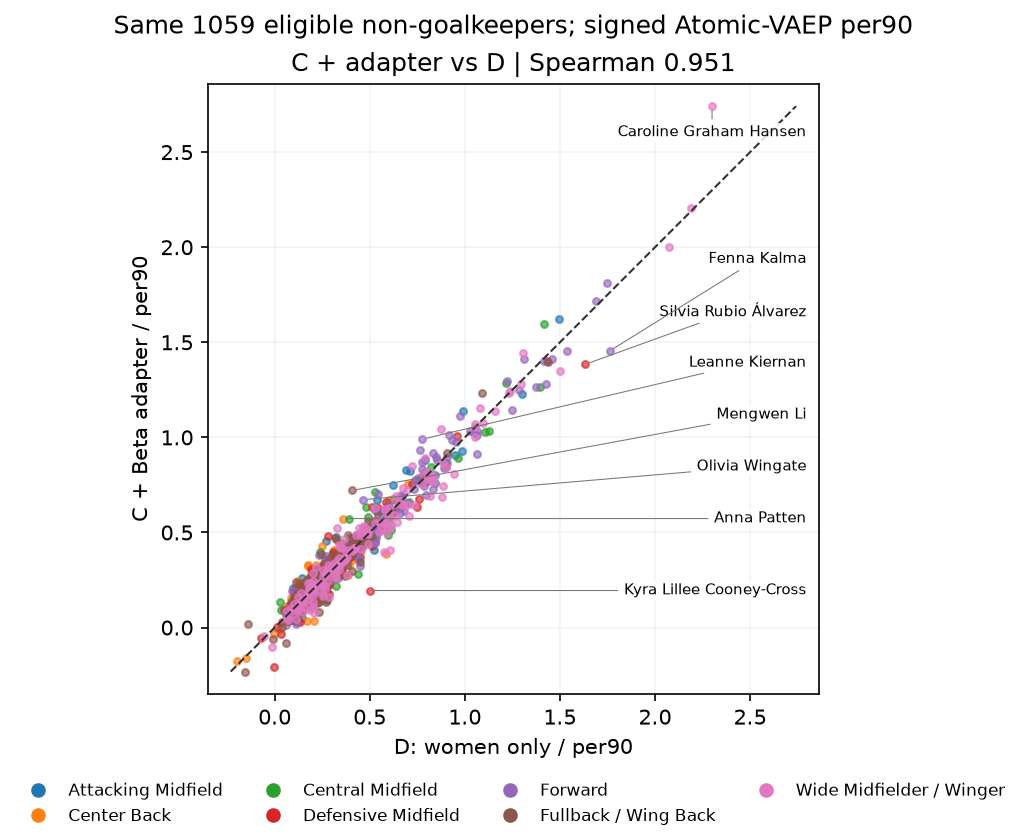

In [14]:
display(Image(filename=str(save_figure(player_plot(players, MAIN_PAIRS, 'per90', annotate=True), FIGURES, '09_per90_overall_scatter'))))

### 7.2 每个位置组内的每90分钟排名
沿用第6.2节的完整位置组和指标定义。

In [15]:
show_ranking_summary(main_per90_summary.loc[main_per90_summary.position != 'All eligible'].sort_values('players', ascending=False))

主指标：相关性越高、归一化名次差越小，表示排名越接近。


,position,players,spearman,kendall_tau_b,mean_abs_rank_change_fraction
6,Fullback / Wing Back,224,0.8923,0.7337,0.0919
2,Center Back,211,0.8945,0.7314,0.0940
4,Defensive Midfield,168,0.9353,0.8048,0.0701
7,Wide Midfielder / Winger,163,0.9761,0.8749,0.0450
5,Forward,147,0.9816,0.8895,0.0396
3,Central Midfield,83,0.9680,0.8631,0.0485
1,Attacking Midfield,63,0.9585,0.8361,0.0599


其他诊断：固定名次范围及 Top 10 受群体人数影响。


,measure,position,left,right,players,scored_actions,mean_abs_rank_change,exact_rank_agreement_pct,within_2_rank_agreement_pct,within_5_rank_agreement_pct,mean_value_difference,median_value_difference,mean_abs_value_difference,top_k,top_overlap,top_overlap_fraction,boundary_tie,shortlist_is_entire_group
6,per90,Fullback / Wing Back,C_adapter,D,224,142313,20.4911,5.8036,13.8393,28.5714,0.0066,0.0043,0.0377,10,8,0.8,False,False
2,per90,Center Back,C_adapter,D,211,163669,19.7346,4.2654,12.7962,24.6445,0.0091,0.0071,0.0338,10,9,0.9,False,False
4,per90,Defensive Midfield,C_adapter,D,168,101811,11.7143,4.1667,20.8333,43.4524,-0.0007,0.0012,0.0382,10,9,0.9,False,False
7,per90,Wide Midfielder / Winger,C_adapter,D,163,72065,7.2883,9.8160,30.0613,50.3067,-0.0058,-0.0032,0.0469,10,9,0.9,False,False
5,per90,Forward,C_adapter,D,147,58583,5.7823,8.8435,32.6531,63.9456,-0.0034,-0.0075,0.0478,10,9,0.9,False,False
3,per90,Central Midfield,C_adapter,D,83,46795,3.9759,18.0723,51.8072,73.4940,0.0020,-0.0035,0.0443,10,10,1.0,False,False
1,per90,Attacking Midfield,C_adapter,D,63,33475,3.7143,19.0476,47.6190,80.9524,0.0195,0.0062,0.0516,10,10,1.0,False,False


### 7.3 每90分钟的位置图
重复第6.3节的四类图，位置顺序与人数色标保持可比；超出±10名的球员仍保留在全部统计中。

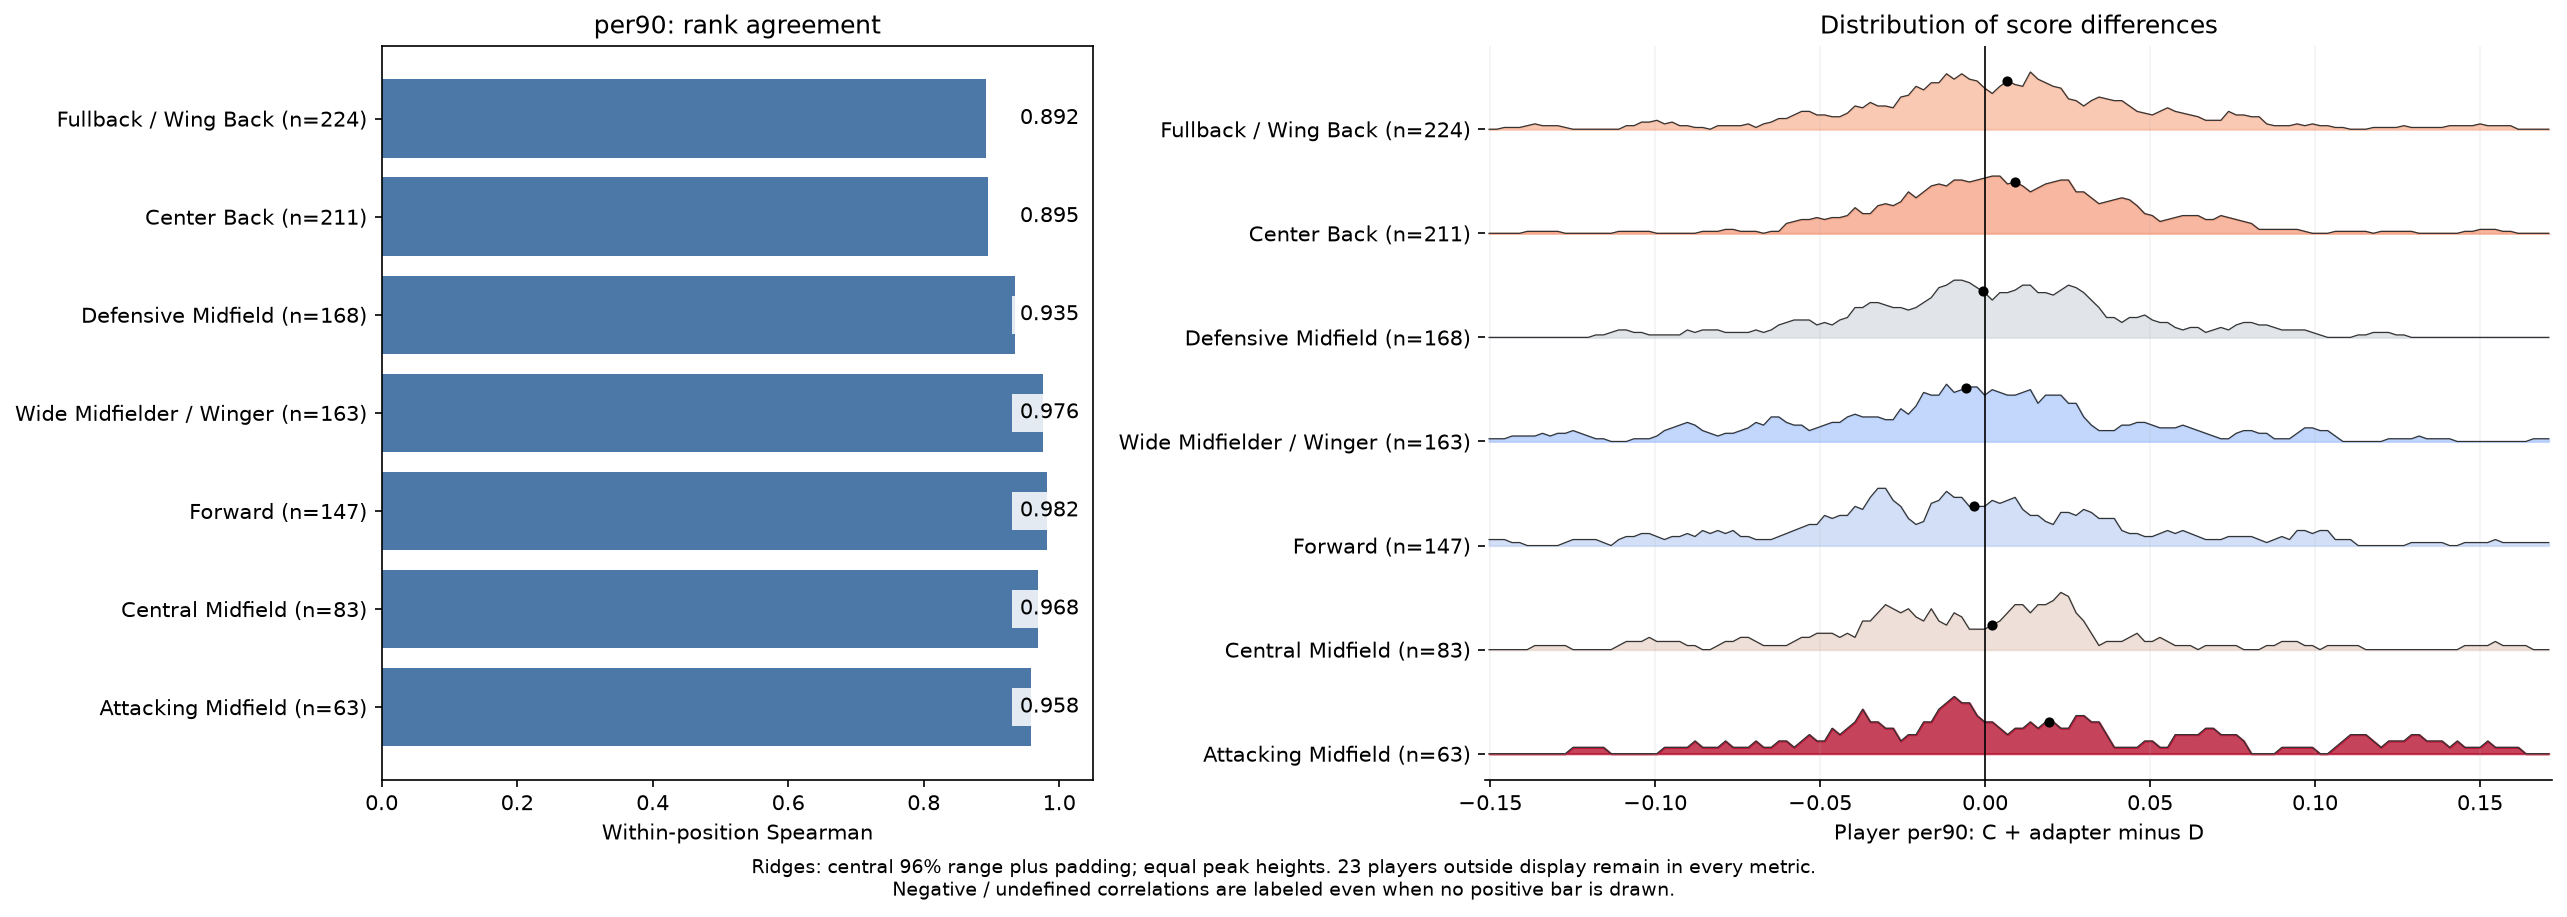

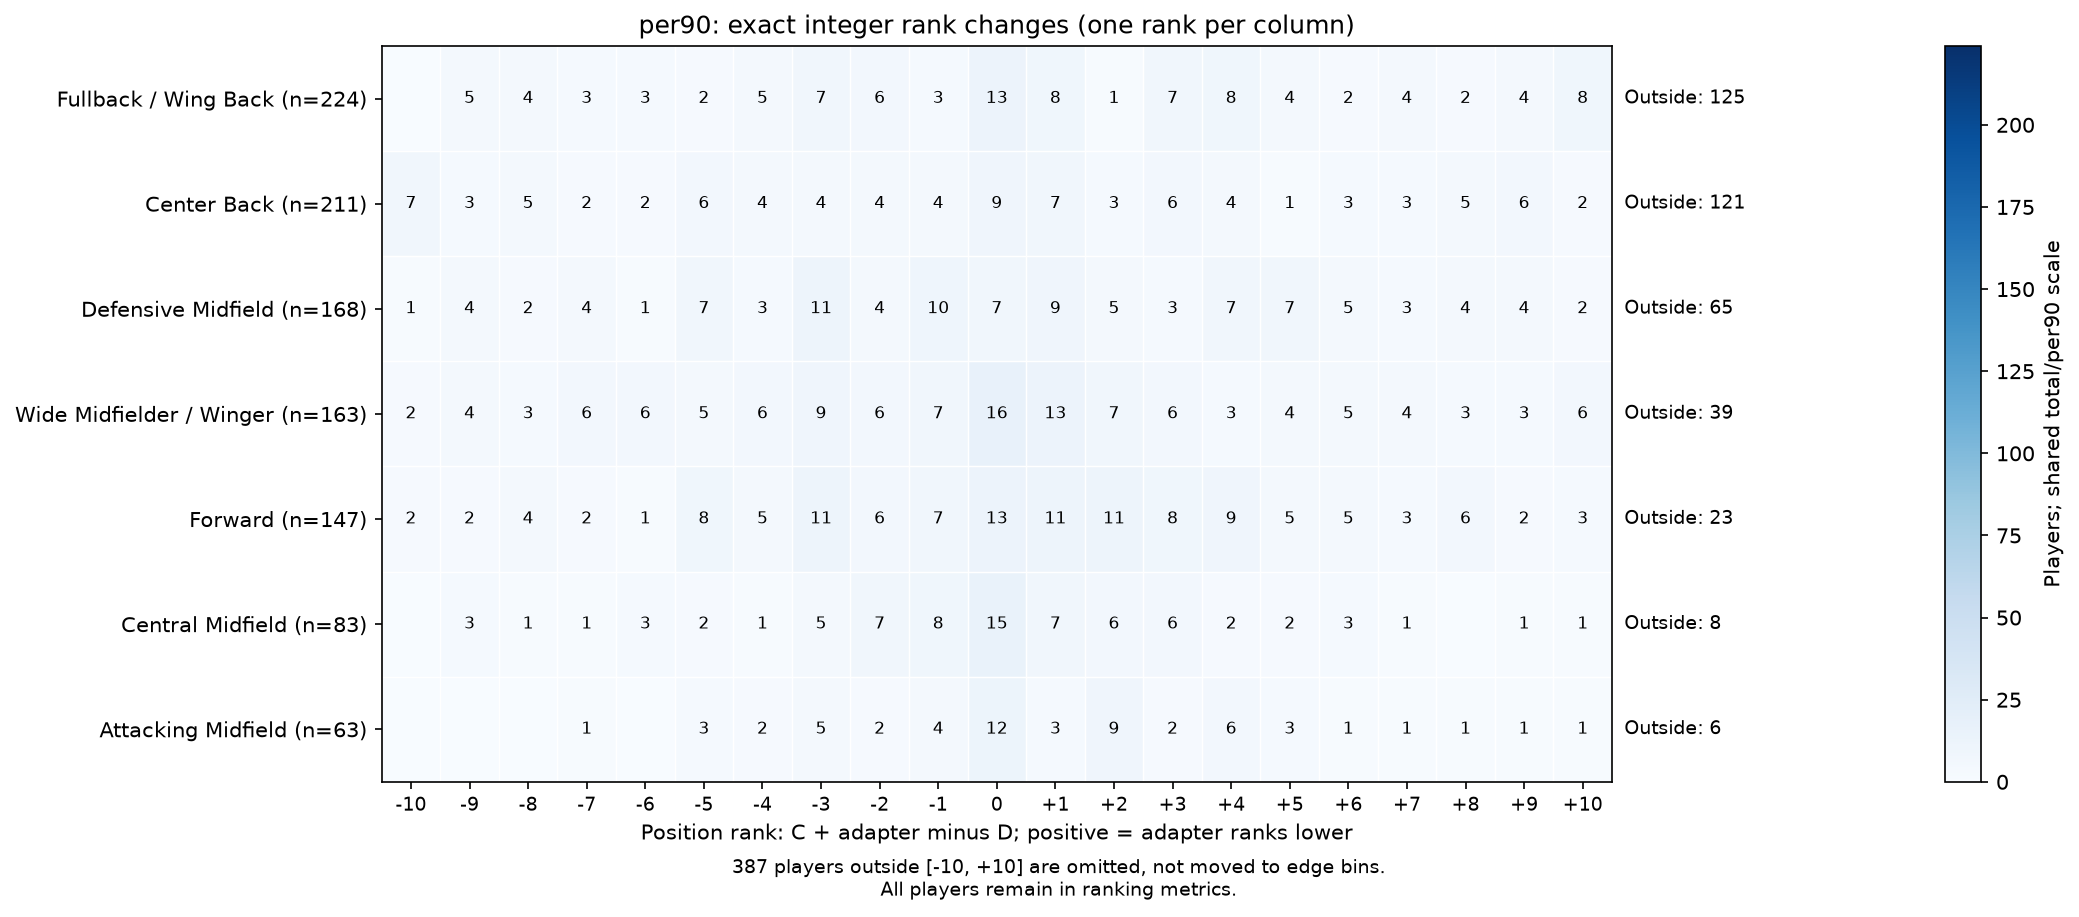

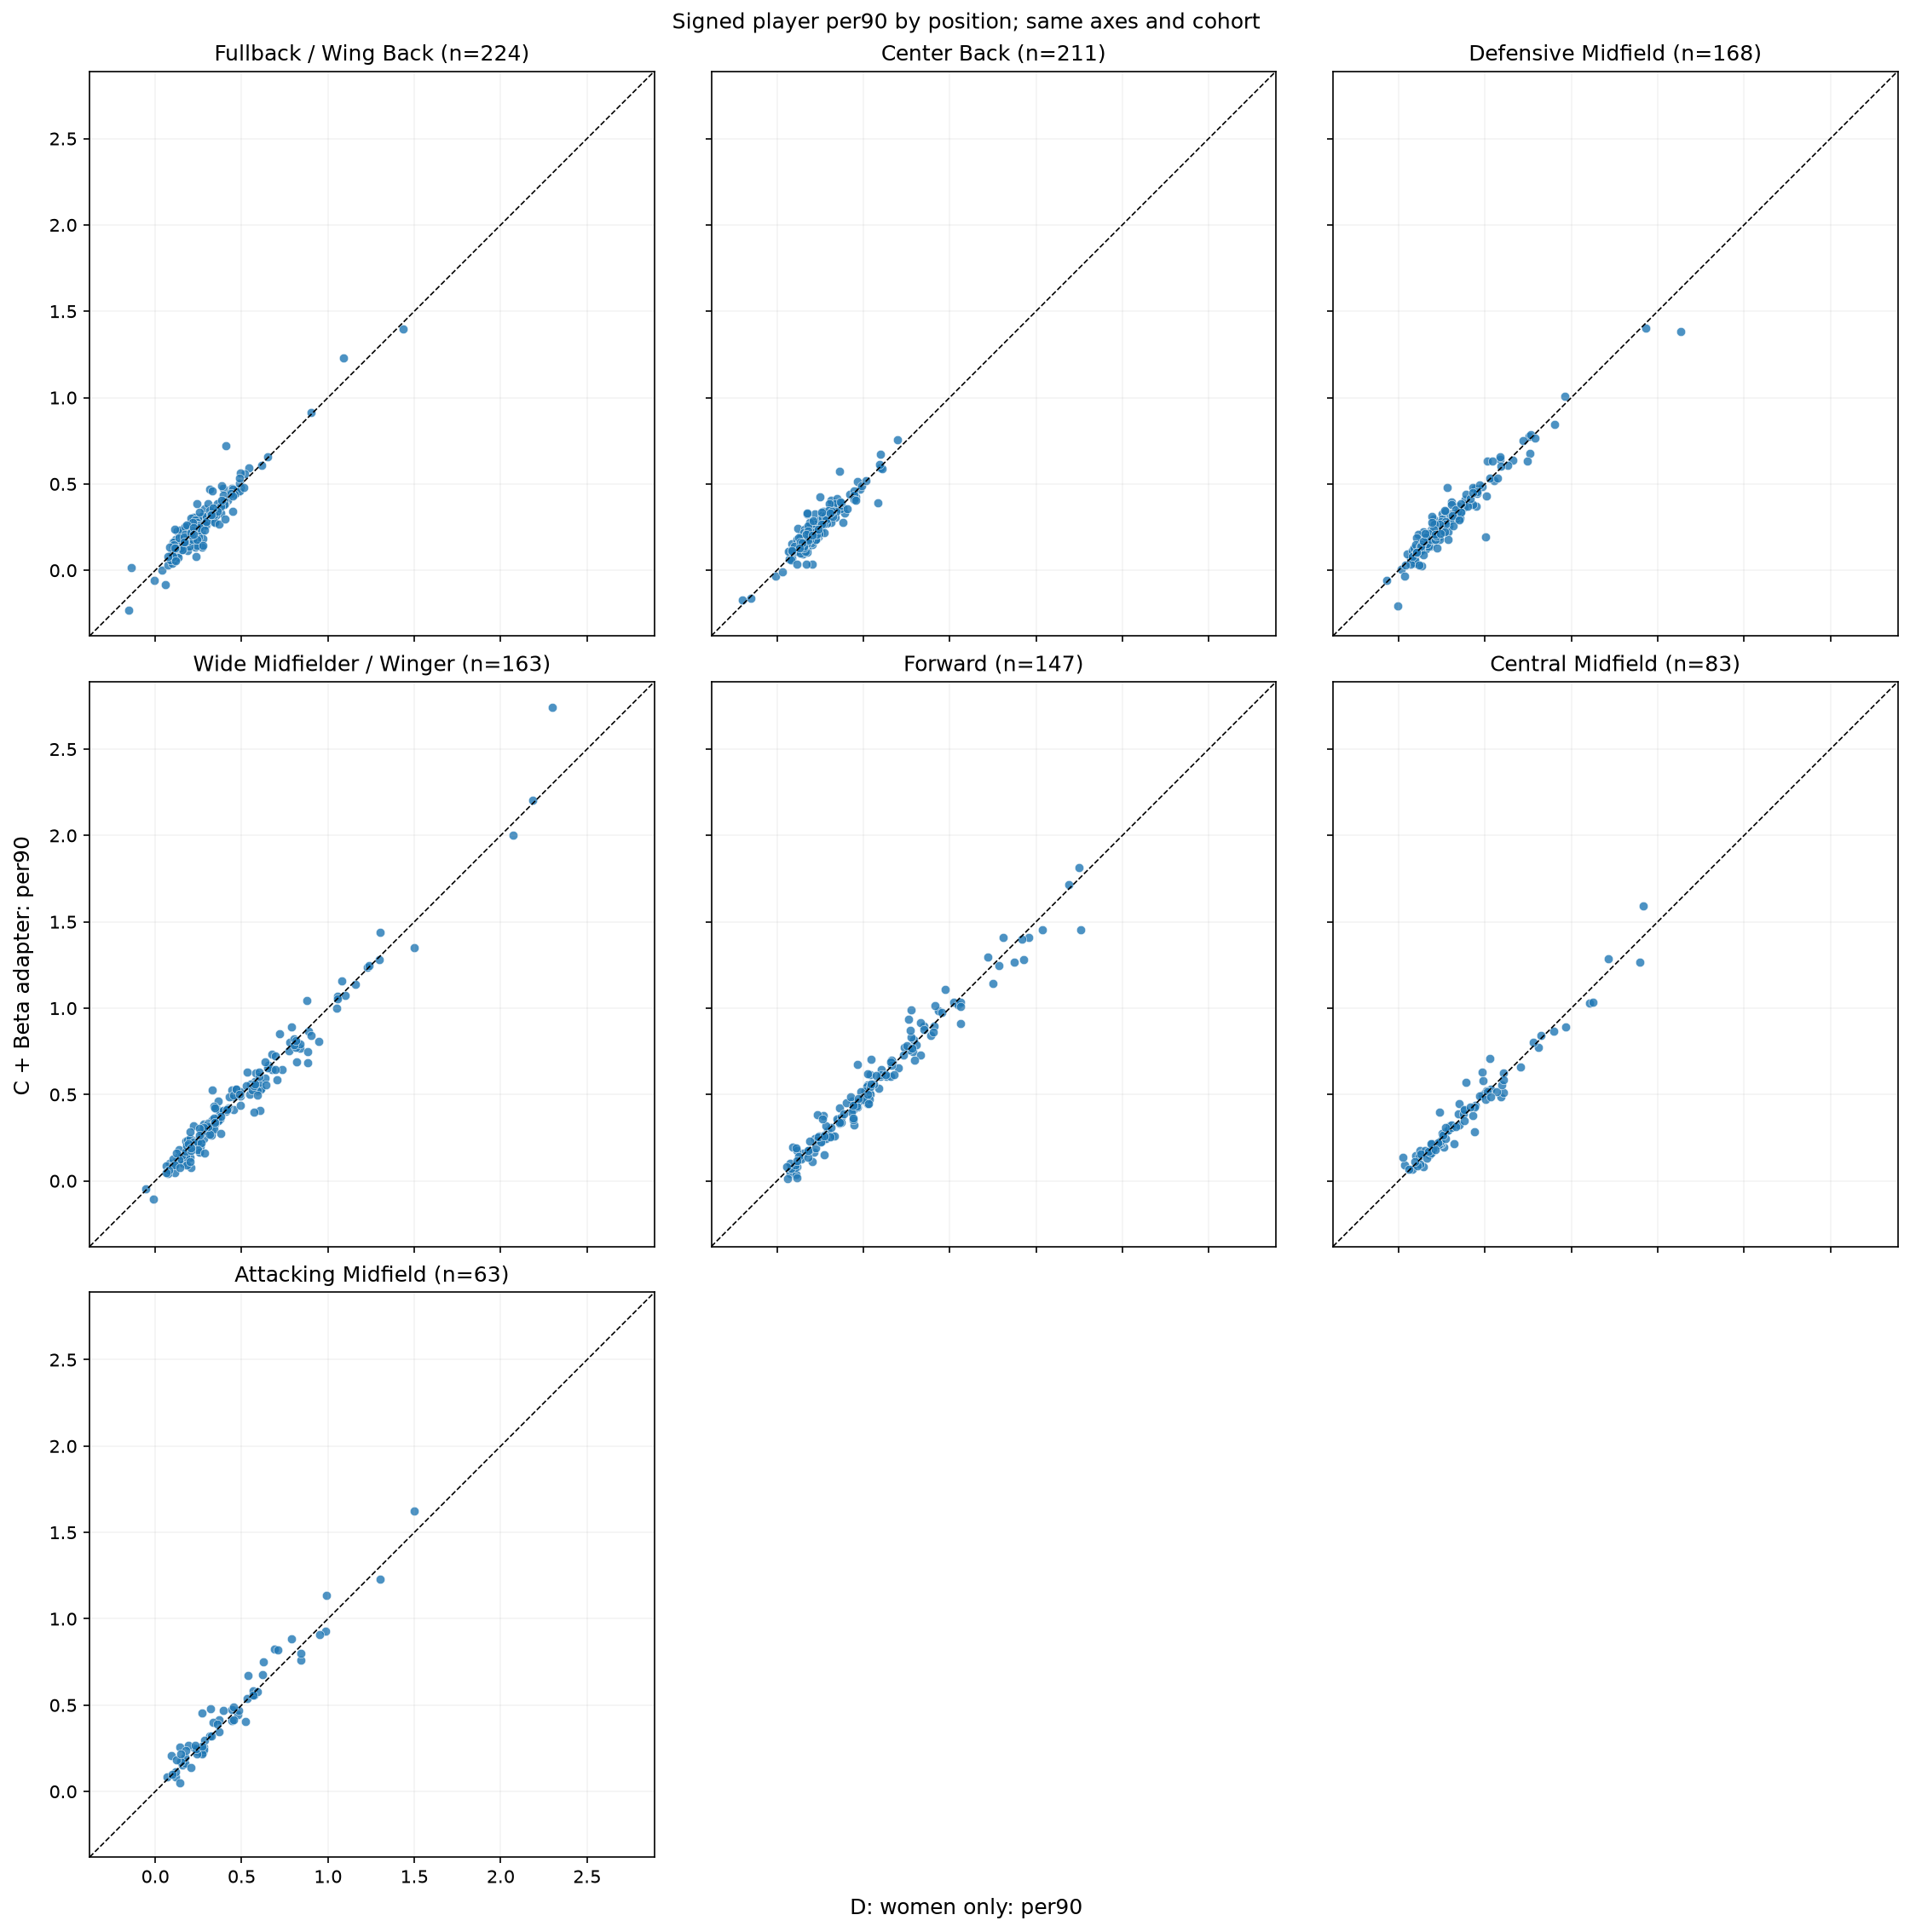

In [16]:
per90_movement = rank_movement_counts(players, MAIN_LEFT, MAIN_RIGHT, 'per90', RANK_MOVEMENT_LIMIT)
per90_movement.to_csv(RESULTS / 'per90_rank_movement_counts.csv', index=False)
display(Image(filename=str(save_figure(position_distribution_plot(players, main_per90_summary, MAIN_PAIRS[0], 'per90'), FIGURES, '10_per90_position_distributions'))))
display(Image(filename=str(save_figure(rank_movement_plot(per90_movement, MAIN_PAIRS[0], 'per90', rank_color_max), FIGURES, '11_per90_rank_movement'))))
display(Image(filename=str(save_figure(position_scatter_plot(players, MAIN_PAIRS[0], 'per90'), FIGURES, '12_per90_position_scatter'))))

### 7.4 并排看总分与每90分钟的模型间差异
这里比较的是“两模型的排名有多接近”，分别在总分、每90分钟两个基础上计算；不是把总分和每90分钟互相关。归一化本身改变哪些人的名单位置，在第8.2节单独分析。

In [17]:
main_rankings = pd.concat([main_total_summary, main_per90_summary], ignore_index=True)
display(main_rankings[['measure', 'position', 'players', 'spearman', 'kendall_tau_b', 'mean_abs_rank_change_fraction']].round(4))
all_rankings = pd.concat([ranking_summary(players, list(MODEL_PATHS), measure, RANK_TOP_K)
                          for measure in ['total', 'per90']], ignore_index=True)
all_rankings.to_csv(RESULTS / 'ranking_agreement.csv', index=False)
changes = pd.concat([player_changes(players, MAIN_PAIRS, measure) for measure in ['total', 'per90']], ignore_index=True)
changes.to_csv(RESULTS / 'player_rank_changes.csv', index=False)
print('正 rank_delta 表示 adapter 名次更靠后；下表展示每90分钟位置内名次差最大的球员。')
display(changes.loc[changes.measure == 'per90'].sort_values(['absolute_rank_change', 'player_id'], ascending=[False, True]).head(20).round(4))

,measure,position,players,spearman,kendall_tau_b,mean_abs_rank_change_fraction
0,total,All eligible,1059,0.9802,0.8828,0.0405
1,total,Attacking Midfield,63,0.9753,0.8730,0.0497
2,total,Center Back,211,0.9671,0.8475,0.0549
3,total,Central Midfield,83,0.9807,0.8930,0.0408
4,total,Defensive Midfield,168,0.9779,0.8752,0.0458
5,total,Forward,147,0.9909,0.9189,0.0298
6,total,Fullback / Wing Back,224,0.9681,0.8547,0.0519
7,total,Wide Midfielder / Winger,163,0.9793,0.8909,0.0386
8,per90,All eligible,1059,0.9511,0.8245,0.0600
9,per90,Attacking Midfield,63,0.9585,0.8361,0.0599


正 rank_delta 表示 adapter 名次更靠后；下表展示每90分钟位置内名次差最大的球员。


,player_id,player_name,position_bucket,test_minutes,action_count,left,right,measure,left_value,right_value,value_delta,left_position_rank,right_position_rank,rank_gain_for_left,rank_delta,absolute_rank_change,position_players,normalized_rank_change
1231,15179,Joelle Wedemeyer,Fullback / Wing Back,219.3177,413.0,C_adapter,D,per90,0.1357,0.2686,-0.1329,192.0,78.0,-114.0,114.0,114.0,224,0.5112
2077,408973,Rebekka Salfelder,Fullback / Wing Back,227.5083,275.0,C_adapter,D,per90,0.1426,0.2768,-0.1343,187.0,75.0,-112.0,112.0,112.0,224,0.5022
1167,10155,María Pilar León Cebrián,Center Back,97.2918,345.0,C_adapter,D,per90,0.2446,0.1203,0.1243,81.0,191.0,110.0,-110.0,110.0,211,0.5238
1094,5000,Stephanie-Elise Catley,Fullback / Wing Back,296.5959,605.0,C_adapter,D,per90,0.0801,0.2342,-0.1541,212.0,103.0,-109.0,109.0,109.0,224,0.4888
1601,48025,Greta Stegemann,Center Back,306.1267,521.0,C_adapter,D,per90,0.0361,0.2063,-0.1702,206.0,105.0,-101.0,101.0,101.0,211,0.4810
1859,136441,Itziar Gastearena Artola,Fullback / Wing Back,280.3960,392.0,C_adapter,D,per90,0.2375,0.1142,0.1233,104.0,204.0,100.0,-100.0,100.0,224,0.4484
1273,19422,Jessica Carter,Center Back,205.3399,435.0,C_adapter,D,per90,0.3251,0.1753,0.1498,46.0,144.0,98.0,-98.0,98.0,211,0.4667
1631,49918,Bibiane Schulze-Solano,Center Back,143.5207,291.0,C_adapter,D,per90,0.3300,0.1757,0.1543,44.0,142.0,98.0,-98.0,98.0,211,0.4667
1240,15290,Ashley Elizabeth Marie Lawrence,Fullback / Wing Back,99.2753,174.0,C_adapter,D,per90,0.1320,0.2309,-0.0989,197.0,108.0,-89.0,89.0,89.0,224,0.3991
1741,62712,Sofie Svava,Fullback / Wing Back,191.6398,423.0,C_adapter,D,per90,0.1455,0.2415,-0.0960,181.0,98.0,-83.0,83.0,83.0,224,0.3722


## 8. 位置 Top 15：保留边界同分，列出完整并集
沿用原 notebook，而不是强行切成恰好15人：**完整位置组的排名≤15都入选**。边界同分扩张名单时，报告实际人数，固定15人的重合比例设为空。

不足15人的位置组排除，不放宽100动作／45分钟门槛。恰好15人的组必然100%重合；`max(0, 30−组内人数)/15` 是名单大小导致的最低可能重合比例，不是经随机机会校正后的指标。

In [18]:
scope = shortlist_scope(players, TOP_K)
if not scope.included.any():
    raise ValueError("No position has at least 15 eligible players; do not relax the cohort filters")
scope.to_csv(RESULTS / 'top15_scope.csv', index=False)
display(scope.round(4))
top_lists = pd.concat([shortlists(players, list(MODEL_PATHS), measure, TOP_K) for measure in ['total', 'per90']], ignore_index=True)
top_lists.to_csv(RESULTS / 'positional_top15.csv', index=False)

,position_bucket,players,included,top_k,min_possible_overlap_pct
0,Fullback / Wing Back,224,True,15,0.0
1,Center Back,211,True,15,0.0
2,Defensive Midfield,168,True,15,0.0
3,Wide Midfielder / Winger,163,True,15,0.0
4,Forward,147,True,15,0.0
5,Central Midfield,83,True,15,0.0
6,Attacking Midfield,63,True,15,0.0


### 8.1 D 与 adapter 的 Top 15：总分和每90分钟各比较一次
先报告各模型入选人数、共同球员、各自独有球员，再列出两个名单的**完整并集**：两种评分、完整位置组名次、名次差、分钟数和动作数。只在名单上重新排名会掩盖真实差异，因此这里保留完整组内名次。

In [19]:
top_summaries, top_details = [], []
for measure in ['total', 'per90']:
    summary, details = positional_top_comparison(players, MAIN_LEFT, MAIN_RIGHT, measure, TOP_K)
    top_summaries.append(summary)
    top_details.append(details)
top_summary = pd.concat(top_summaries, ignore_index=True)
top_details = pd.concat(top_details, ignore_index=True)
top_summary.to_csv(RESULTS / 'top15_model_comparison.csv', index=False)
top_details.to_csv(RESULTS / 'top15_model_union.csv', index=False)
display(top_summary.round(4))
overlap_change = top_summary.pivot(index='position_bucket', columns='measure', values='overlap_pct')
overlap_change['per90_minus_total_pp'] = overlap_change.per90 - overlap_change.total
overlap_change.to_csv(RESULTS / 'top15_overlap_change.csv')
print('每90分钟相对总分的模型间名单重合率变化（百分点）：')
display(overlap_change.round(4))
with pd.option_context('display.max_rows', None):
    for (position, measure), union in top_details.groupby(['position_bucket', 'measure'], sort=False):
        print(position, '|', measure, '| left = adapter, right = D；完整名单并集')
        display(union[['player_id', 'player_name', 'left_value', 'right_value', 'left_rank', 'right_rank',
                       'rank_delta', 'left_in_top', 'right_in_top', 'test_minutes', 'action_count']].round(4))

,position_bucket,measure,left,right,players,top_k,left_selected,right_selected,shared_players,left_only_players,right_only_players,overlap_pct,boundary_tie,min_possible_overlap_pct
0,Attacking Midfield,total,C_adapter,D,63,15,15,15,13,2,2,86.6667,False,0.0
1,Center Back,total,C_adapter,D,211,15,15,15,12,3,3,80.0000,False,0.0
2,Central Midfield,total,C_adapter,D,83,15,15,15,13,2,2,86.6667,False,0.0
3,Defensive Midfield,total,C_adapter,D,168,15,15,15,13,2,2,86.6667,False,0.0
4,Forward,total,C_adapter,D,147,15,15,15,15,0,0,100.0000,False,0.0
5,Fullback / Wing Back,total,C_adapter,D,224,15,15,15,13,2,2,86.6667,False,0.0
6,Wide Midfielder / Winger,total,C_adapter,D,163,15,15,15,14,1,1,93.3333,False,0.0
7,Attacking Midfield,per90,C_adapter,D,63,15,15,15,13,2,2,86.6667,False,0.0
8,Center Back,per90,C_adapter,D,211,15,15,15,12,3,3,80.0000,False,0.0
9,Central Midfield,per90,C_adapter,D,83,15,15,15,13,2,2,86.6667,False,0.0


每90分钟相对总分的模型间名单重合率变化（百分点）：


measure,per90,total,per90_minus_total_pp
position_bucket,,,
Attacking Midfield,86.6667,86.6667,0.0000
Center Back,80.0000,80.0000,0.0000
Central Midfield,86.6667,86.6667,0.0000
Defensive Midfield,86.6667,86.6667,0.0000
Forward,86.6667,100.0000,-13.3333
Fullback / Wing Back,80.0000,86.6667,-6.6667
Wide Midfielder / Winger,93.3333,93.3333,0.0000


Attacking Midfield | total | left = adapter, right = D；完整名单并集


,player_id,player_name,left_value,right_value,left_rank,right_rank,rank_delta,left_in_top,right_in_top,test_minutes,action_count
0,128663,Cristina Librán,4.6301,4.3128,1.0,4.0,-3.0,True,True,853.1714,1322.0
1,5096,Savannah McCaskill,4.5585,4.6755,2.0,1.0,1.0,True,True,738.2197,1241.0
2,10220,Kosovare Asllani,4.2817,4.5401,3.0,2.0,1.0,True,True,313.8703,489.0
3,10108,Pernille Mosegaard Harder,4.2651,4.4622,4.0,3.0,1.0,True,True,422.7060,619.0
4,47022,Laura Freigang,4.0158,3.2189,5.0,12.0,-7.0,True,True,539.5048,657.0
5,32460,Karólína Lea Vilhjálmsdóttir,3.7997,3.8738,7.0,5.0,2.0,True,True,590.0391,778.0
6,24396,Jovana Damnjanović,3.9474,3.6367,6.0,8.0,-2.0,True,True,218.6116,280.0
7,15227,Verónica Boquete Giadáns,3.5508,3.8075,9.0,6.0,3.0,True,True,720.5091,1024.0
8,321538,Natasha Kowalski,2.9129,3.7717,14.0,7.0,7.0,True,True,646.7911,689.0
9,409186,Laura Requena Sánchez,3.7609,3.4562,8.0,9.0,-1.0,True,True,865.8255,1151.0


Center Back | total | left = adapter, right = D；完整名单并集


... (21 outputs left out)

Fullback / Wing Back | per90 | left = adapter, right = D；完整名单并集


,player_id,player_name,left_value,right_value,left_rank,right_rank,rank_delta,left_in_top,right_in_top,test_minutes,action_count
203,10376,Carolin Simon,1.3950,1.4354,1.0,1.0,0.0,True,True,70.0994,145.0
204,10215,Fridolina Rolfö,1.2319,1.0882,2.0,2.0,0.0,True,True,87.8964,288.0
205,46224,Lucia Di Guglielmo,0.9155,0.9039,3.0,3.0,0.0,True,True,392.9931,770.0
206,131575,Mengwen Li,0.7213,0.4086,4.0,26.0,-22.0,True,False,117.5592,116.0
207,10148,Marta Torrejón Moya,0.6592,0.6504,5.0,4.0,1.0,True,True,502.3130,1229.0
208,415257,Laura Camino Fernández,0.6081,0.6157,6.0,5.0,1.0,True,True,293.8612,385.0
209,25492,Giulia Gwinn,0.5931,0.5436,7.0,6.0,1.0,True,True,460.3929,862.0
210,46639,Ona Batlle Pascual,0.5580,0.5179,9.0,7.0,2.0,True,True,386.2781,975.0
211,50175,Paula Tomás Serer,0.5624,0.4922,8.0,10.0,-2.0,True,True,274.9855,544.0
212,84730,Anna Gerhardt,0.4805,0.5105,14.0,8.0,6.0,True,True,779.7330,1073.0


Wide Midfielder / Winger | per90 | left = adapter, right = D；完整名单并集


,player_id,player_name,left_value,right_value,left_rank,right_rank,rank_delta,left_in_top,right_in_top,test_minutes,action_count
221,10386,Caroline Graham Hansen,2.7415,2.2998,1.0,1.0,0.0,True,True,216.1109,489.0
222,222682,Salma Paralluelo Ayingono,2.2064,2.1872,2.0,2.0,0.0,True,True,273.1308,531.0
223,15214,Ewa Pajor,2.0007,2.0741,3.0,3.0,0.0,True,True,434.9164,562.0
224,32838,Claudia Pina Medina,1.4413,1.3040,4.0,5.0,-1.0,True,True,404.2884,896.0
225,338839,Leela Egli,1.3503,1.5010,5.0,4.0,1.0,True,True,99.5193,110.0
226,105708,Kerolin Nicoli Israel Ferraz,1.2811,1.2947,6.0,6.0,0.0,True,True,315.6969,475.0
227,62710,Johanna Rytting-Kaneryd,1.2465,1.2382,7.0,7.0,0.0,True,True,138.6601,184.0
228,6818,Hayley Emma Raso,1.2349,1.2300,8.0,8.0,0.0,True,True,122.2664,222.0
229,15555,Lauren Hemp,1.1562,1.0811,9.0,11.0,-2.0,True,True,705.5225,962.0
230,46941,Vivien Endemann,1.1376,1.1593,10.0,9.0,1.0,True,True,347.4174,506.0


### 8.2 每个模型内部：总分改成每90分钟后，谁进入或退出？
对 D、adapter 分别比较总分名单与每90分钟名单，报告保留、进入、退出人数和完整并集。`rank_improvement_per90 = 总分名次 − 每90分钟名次`，正数表示归一化后上升。

这一节隔离出“出场时间归一化”的影响，不把它与模型差异混为一谈。

In [20]:
normalization_summary, normalization_details = normalization_top_comparison(players, MAIN_MODELS, TOP_K)
normalization_summary.to_csv(RESULTS / 'top15_normalization_summary.csv', index=False)
normalization_details.to_csv(RESULTS / 'top15_normalization_union.csv', index=False)
display(normalization_summary.round(4))
with pd.option_context('display.max_rows', None):
    for (position, model), union in normalization_details.groupby(['position_bucket', 'model'], sort=False):
        print(position, '|', model, '| 总分与每90分钟名单的完整并集')
        display(union[['player_id', 'player_name', 'total_value', 'per90_value', 'total_rank', 'per90_rank',
                       'rank_improvement_per90', 'in_total_top', 'in_per90_top', 'test_minutes', 'action_count']].round(4))

,position_bucket,model,players,top_k,left_selected,right_selected,shared_players,left_only_players,right_only_players,overlap_pct,boundary_tie,min_possible_overlap_pct,retained_players,entrants,exits
0,Attacking Midfield,D,63,15,15,15,6,9,9,40.0000,False,0.0,6,9,9
1,Attacking Midfield,C_adapter,63,15,15,15,8,7,7,53.3333,False,0.0,8,7,7
2,Center Back,D,211,15,15,15,3,12,12,20.0000,False,0.0,3,12,12
3,Center Back,C_adapter,211,15,15,15,2,13,13,13.3333,False,0.0,2,13,13
4,Central Midfield,D,83,15,15,15,7,8,8,46.6667,False,0.0,7,8,8
5,Central Midfield,C_adapter,83,15,15,15,6,9,9,40.0000,False,0.0,6,9,9
6,Defensive Midfield,D,168,15,15,15,4,11,11,26.6667,False,0.0,4,11,11
7,Defensive Midfield,C_adapter,168,15,15,15,4,11,11,26.6667,False,0.0,4,11,11
8,Forward,D,147,15,15,15,7,8,8,46.6667,False,0.0,7,8,8
9,Forward,C_adapter,147,15,15,15,7,8,8,46.6667,False,0.0,7,8,8


Attacking Midfield | D | 总分与每90分钟名单的完整并集


,player_id,player_name,total_value,per90_value,total_rank,per90_rank,rank_improvement_per90,in_total_top,in_per90_top,test_minutes,action_count
0,5096,Savannah McCaskill,4.6755,0.5700,1.0,14.0,-13.0,True,True,738.2197,1241.0
1,24396,Jovana Damnjanović,3.6367,1.4972,8.0,1.0,7.0,True,True,218.6116,280.0
2,10220,Kosovare Asllani,4.5401,1.3018,2.0,2.0,0.0,True,True,313.8703,489.0
3,10108,Pernille Mosegaard Harder,4.4622,0.9501,3.0,5.0,-2.0,True,True,422.7060,619.0
4,47285,Taylor Kornieck,1.8167,0.9888,30.0,3.0,27.0,False,True,165.3608,199.0
5,128663,Cristina Librán,4.3128,0.4550,4.0,23.0,-19.0,True,False,853.1714,1322.0
6,4641,Francesca Kirby,0.9840,0.9864,39.0,4.0,35.0,False,True,89.7796,111.0
7,32460,Karólína Lea Vilhjálmsdóttir,3.8738,0.5909,5.0,13.0,-8.0,True,True,590.0391,778.0
8,15227,Verónica Boquete Giadáns,3.8075,0.4756,6.0,22.0,-16.0,True,False,720.5091,1024.0
9,10259,Lina Magull,3.4465,0.8453,10.0,6.0,4.0,True,True,366.9346,661.0


Attacking Midfield | C_adapter | 总分与每90分钟名单的完整并集


,player_id,player_name,total_value,per90_value,total_rank,per90_rank,rank_improvement_per90,in_total_top,in_per90_top,test_minutes,action_count
24,128663,Cristina Librán,4.6301,0.4884,1.0,20.0,-19.0,True,False,853.1714,1322.0
25,24396,Jovana Damnjanović,3.9474,1.6251,6.0,1.0,5.0,True,True,218.6116,280.0
26,5096,Savannah McCaskill,4.5585,0.5557,2.0,18.0,-16.0,True,False,738.2197,1241.0
27,10220,Kosovare Asllani,4.2817,1.2278,3.0,2.0,1.0,True,True,313.8703,489.0
28,47285,Taylor Kornieck,2.0885,1.1367,27.0,3.0,24.0,False,True,165.3608,199.0
29,10108,Pernille Mosegaard Harder,4.2651,0.9081,4.0,5.0,-1.0,True,True,422.7060,619.0
30,4641,Francesca Kirby,0.9273,0.9296,41.0,4.0,37.0,False,True,89.7796,111.0
31,47022,Laura Freigang,4.0158,0.6699,5.0,13.0,-8.0,True,True,539.5048,657.0
32,4638,Drew Spence,2.9318,0.8835,13.0,6.0,7.0,True,True,298.6769,485.0
33,32460,Karólína Lea Vilhjálmsdóttir,3.7997,0.5796,7.0,15.0,-8.0,True,True,590.0391,778.0


Center Back | D | 总分与每90分钟名单的完整并集


... (19 outputs left out)

Wide Midfielder / Winger | D | 总分与每90分钟名单的完整并集


,player_id,player_name,total_value,per90_value,total_rank,per90_rank,rank_improvement_per90,in_total_top,in_per90_top,test_minutes,action_count
294,15214,Ewa Pajor,10.0229,2.0741,1.0,3.0,-2.0,True,True,434.9164,562.0
295,10386,Caroline Graham Hansen,5.5223,2.2998,9.0,1.0,8.0,True,True,216.1109,489.0
296,15555,Lauren Hemp,8.4746,1.0811,2.0,11.0,-9.0,True,True,705.5225,962.0
297,222682,Salma Paralluelo Ayingono,6.6377,2.1872,6.0,2.0,4.0,True,True,273.1308,531.0
298,50020,Antionette Oyedupe Payne,7.6787,0.6348,3.0,45.0,-42.0,True,False,1088.6392,1182.0
299,42247,Morgan Weaver,7.2752,0.7790,4.0,32.0,-28.0,True,False,840.5724,884.0
300,338839,Leela Egli,1.6598,1.5010,74.0,4.0,70.0,False,True,99.5193,110.0
301,26156,Rasheedat Busayo Ajibade,7.0504,1.0979,5.0,10.0,-5.0,True,True,577.9650,801.0
302,32838,Claudia Pina Medina,5.8579,1.3040,7.0,5.0,2.0,True,True,404.2884,896.0
303,105708,Kerolin Nicoli Israel Ferraz,4.5415,1.2947,14.0,6.0,8.0,True,True,315.6969,475.0


Wide Midfielder / Winger | C_adapter | 总分与每90分钟名单的完整并集


,player_id,player_name,total_value,per90_value,total_rank,per90_rank,rank_improvement_per90,in_total_top,in_per90_top,test_minutes,action_count
315,15214,Ewa Pajor,9.6683,2.0007,1.0,3.0,-2.0,True,True,434.9164,562.0
316,10386,Caroline Graham Hansen,6.5830,2.7415,7.0,1.0,6.0,True,True,216.1109,489.0
317,15555,Lauren Hemp,9.0634,1.1562,2.0,9.0,-7.0,True,True,705.5225,962.0
318,222682,Salma Paralluelo Ayingono,6.6960,2.2064,6.0,2.0,4.0,True,True,273.1308,531.0
319,42247,Morgan Weaver,7.4887,0.8018,3.0,24.0,-21.0,True,False,840.5724,884.0
320,50020,Antionette Oyedupe Payne,7.1751,0.5932,4.0,47.0,-43.0,True,False,1088.6392,1182.0
321,32838,Claudia Pina Medina,6.4744,1.4413,8.0,4.0,4.0,True,True,404.2884,896.0
322,26156,Rasheedat Busayo Ajibade,6.8981,1.0742,5.0,11.0,-6.0,True,True,577.9650,801.0
323,338839,Leela Egli,1.4931,1.3503,77.0,5.0,72.0,False,True,99.5193,110.0
324,105708,Kerolin Nicoli Israel Ferraz,4.4939,1.2811,12.0,6.0,6.0,True,True,315.6969,475.0


## 9. 辅助比较与出场时间敏感性
主线仍是 D vs C+adapter。C−D、C+adapter−C 只解释加层前后发生什么；A和新继续训练只放在补充预测与总体排名表中，旧继续训练不分析。

另将分钟门槛提高到180／450，查看主要模型的排名比较；这改变了球员群体，不是新的独立实验。

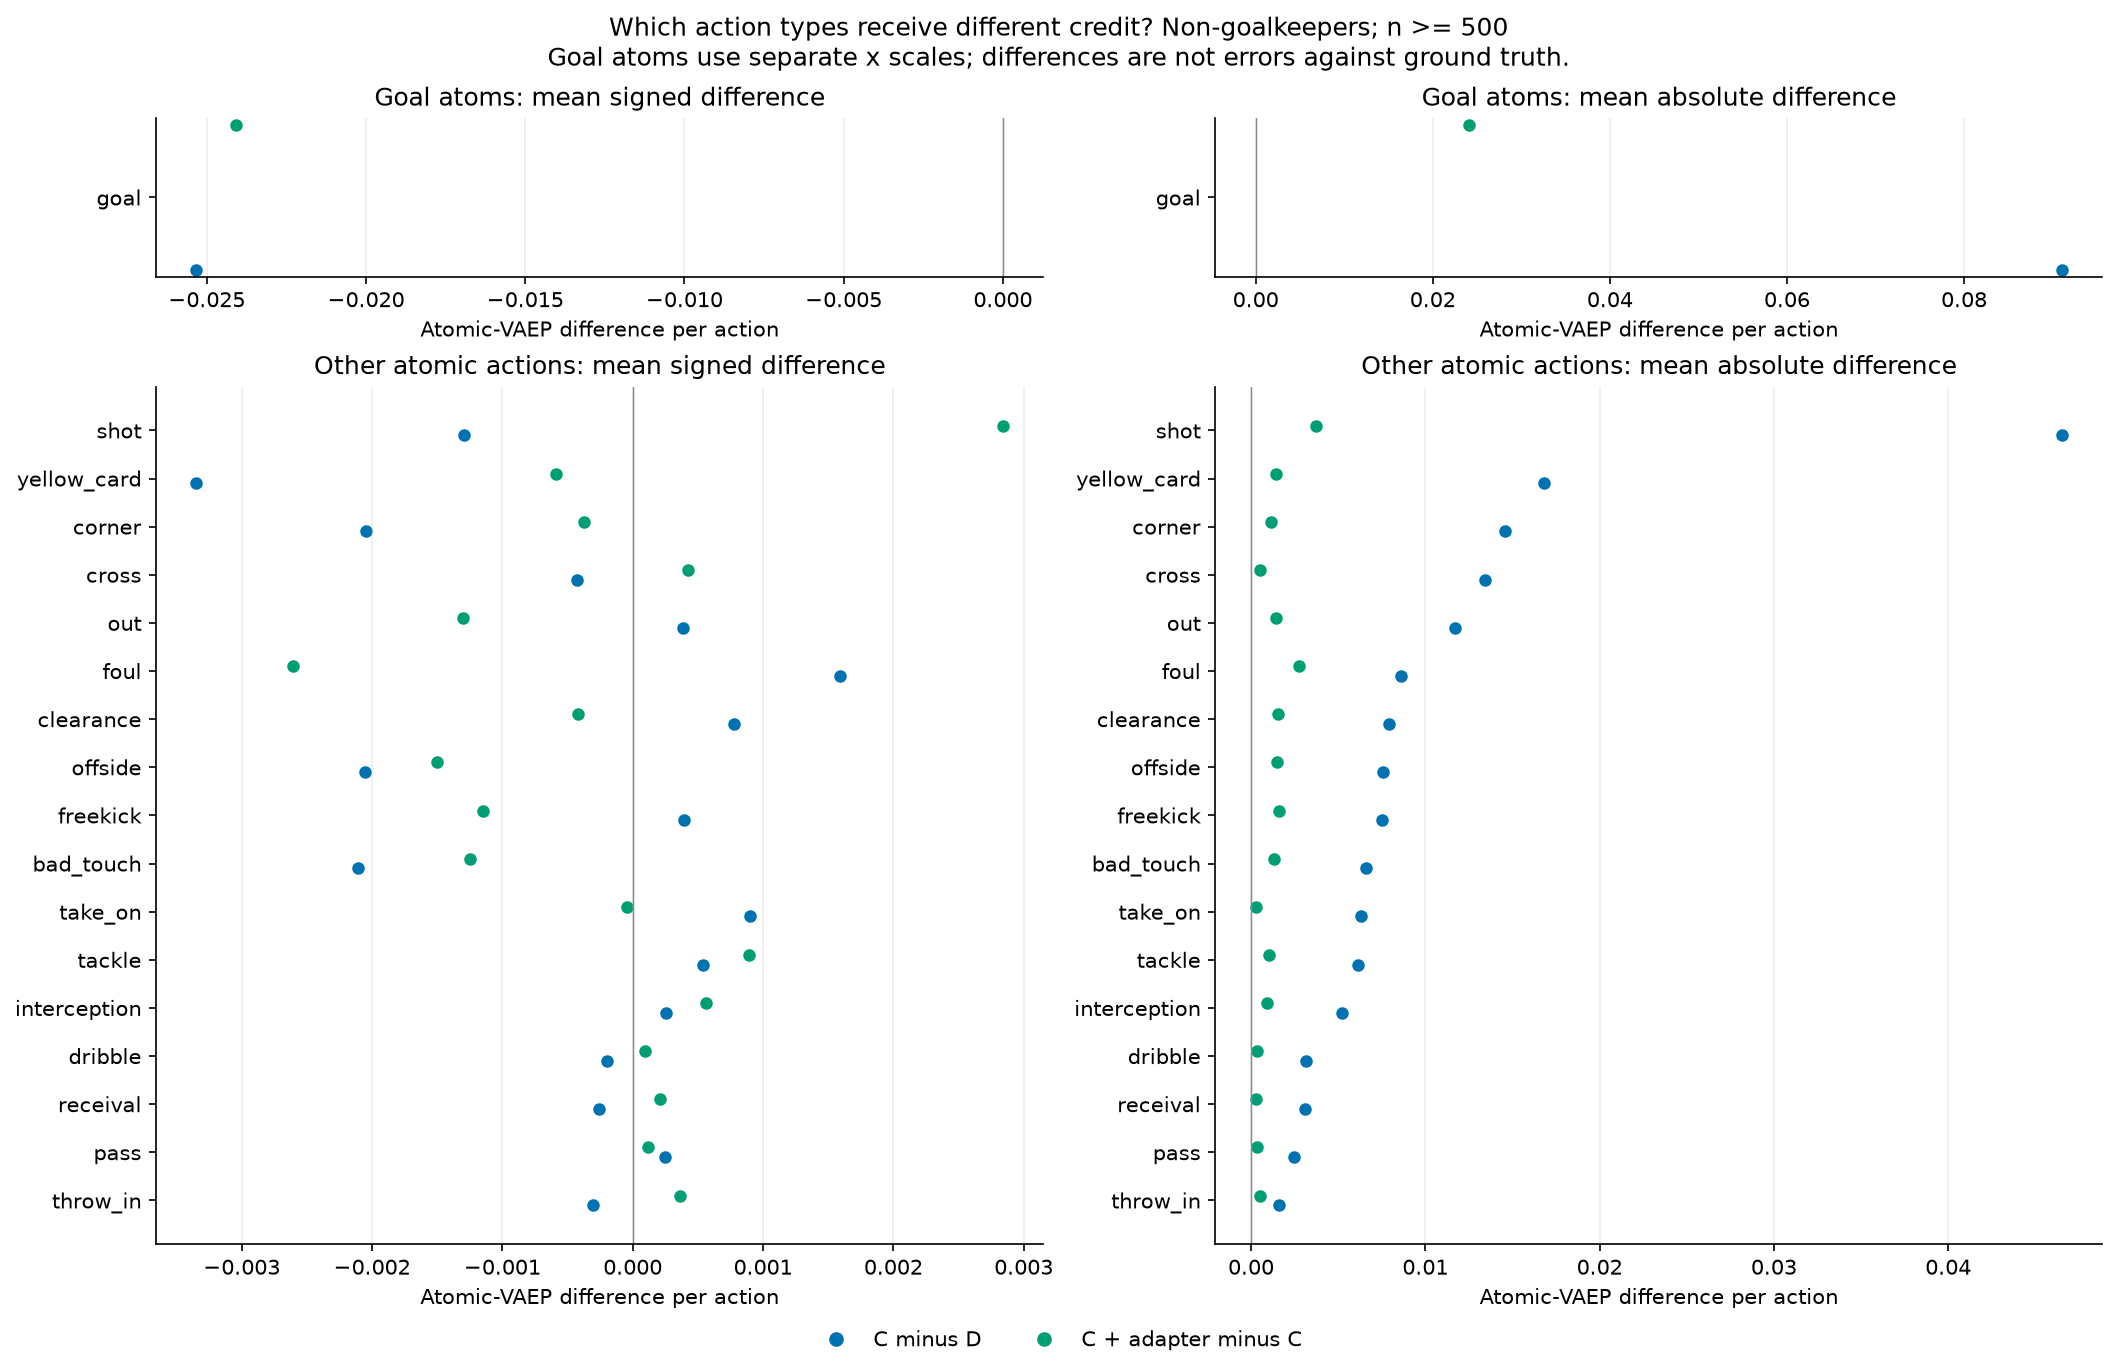

target,concedes,scores
model,,
A,0.008646,0.034907
C,0.008507,0.034542
C_adapter,0.008454,0.034471
C_continued,0.008474,0.034502
D,0.008529,0.034910


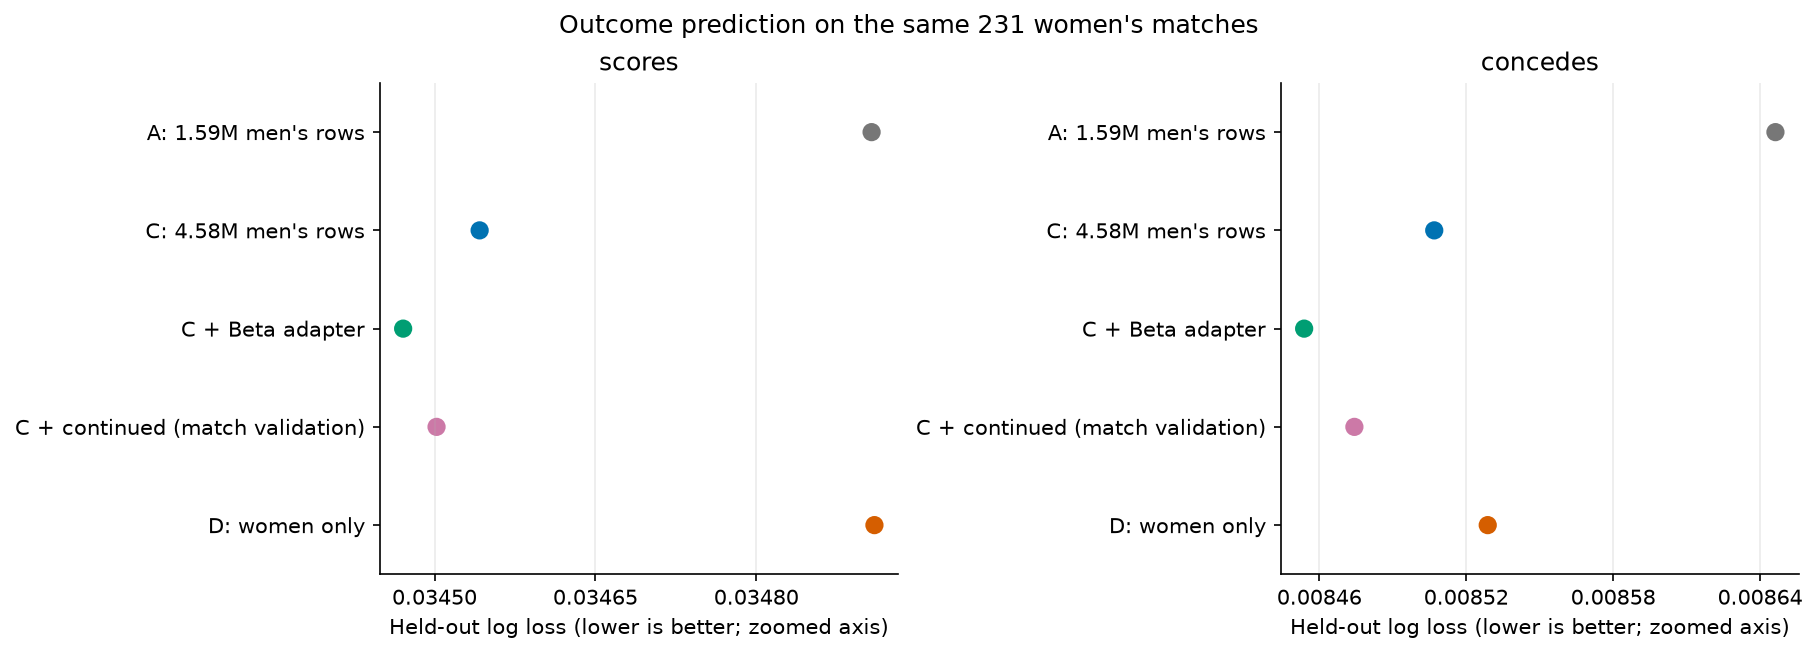

,measure,left,right,players,spearman,kendall_tau_b,mean_abs_rank_change_fraction
0,total,A,C,1059,0.9887,0.9117,0.0309
1,total,A,C_adapter,1059,0.9859,0.9016,0.0345
2,total,A,C_continued,1059,0.9877,0.9076,0.0323
3,total,A,D,1059,0.9772,0.8744,0.0436
4,total,C,C_adapter,1059,0.9988,0.9722,0.0102
5,total,C,C_continued,1059,0.9992,0.9769,0.0084
6,total,C,D,1059,0.9812,0.8851,0.0396
7,total,C_adapter,C_continued,1059,0.9989,0.9736,0.0094
8,total,C_adapter,D,1059,0.9802,0.8828,0.0405
9,total,C_continued,D,1059,0.9822,0.8886,0.0386


,minimum_minutes,players,spearman,kendall_tau_b,mean_abs_rank_change_fraction
0,45,1059,0.9511,0.8245,0.0600
8,180,873,0.9540,0.8291,0.0586
16,450,417,0.9699,0.8557,0.0510


In [21]:
context_differences = action_summary(analysis_actions, analysis_values, CONTEXT_PAIRS)
context_differences.to_csv(RESULTS / 'action_type_source_context.csv', index=False)
display(Image(filename=str(save_figure(action_plot(context_differences, CONTEXT_PAIRS), FIGURES, '13_source_context'))))
display(metrics.pivot(index='model', columns='target', values='log_loss').reindex(list(MODEL_PATHS)))
display(Image(filename=str(save_figure(probability_plot(metrics, list(MODEL_PATHS)), FIGURES, '14_probability_supplement'))))
display(all_rankings.loc[all_rankings.position == 'All eligible', ['measure', 'left', 'right', 'players',
                        'spearman', 'kendall_tau_b', 'mean_abs_rank_change_fraction']].round(4))
sensitivity = []
for minimum in sorted(set([MIN_MINUTES, 180, 450])):
    subset = players.loc[players.test_minutes.ge(minimum)]
    if len(subset) >= 2:
        current = ranking_summary(subset, [MAIN_LEFT, MAIN_RIGHT], 'per90', RANK_TOP_K)
        sensitivity.append(current.assign(minimum_minutes=minimum))
sensitivity = pd.concat(sensitivity, ignore_index=True)
sensitivity.to_csv(RESULTS / 'minutes_sensitivity.csv', index=False)
display(sensitivity.loc[sensitivity.position == 'All eligible', ['minimum_minutes', 'players', 'spearman',
                        'kendall_tau_b', 'mean_abs_rank_change_fraction']].round(4))

## 10. 阅读边界与重新画图
- 与原 enriched notebook 一样，动作层分析先于球员筛选；球员总分和每90分钟严格复用同一群体。
- 分布图、空间颜色和名次热图存在显示范围，但完整数据始终留在统计和CSV中。不能把没画出的极端值理解成不存在。
- 原 notebook 的模型是男女模型；这里替换为 **C+adapter vs D**，保留它的分析方法，不复用它训练的估计器。
- 本包没有训练集输入，所以不复刻训练集概率诊断；没有重新训练或改变现有模型。训练局限和测试后选择需如实披露。
- 概率指标有实际进球／失球标签；贡献分、排名和名单比较没有球员贡献真值，不能因此证明谁选出了更强阵容。

图在 `results/figures/`；完整动作概率与估值在 `results/action_values.parquet`；球员总分、每90分钟和名次在 `results/player_values.csv`；模型间名单并集与归一化名单并集分别在 `top15_model_union.csv`、`top15_normalization_union.csv`。原实验和原 enriched notebook 不改动。